# SAT-Dengue V2 — Stage 2 Official EDA — Residence, Onset and DIVIPOLA

## Objective
Perform a reproducible, bounded initial EDA focused on:
- `data/raw/dengue.csv`
- `data/raw/dengue_grave.csv`

And only complementary coverage/missingness review on:
- `data/raw/google_earth_engine.csv`

## Approved decisions used in this notebook
- Epidemiological geography: **residence** fields.
- Epidemiological date: **`INI_SIN`** (onset of symptoms), without automatic substitution by `FEC_NOT`.
- Geographic scope: municipalities belonging to **Tolima** and **Meta** by residence.
- Descriptive unit: **municipality-month**, keeping dengue and severe dengue files separate.

## Scope boundary
This notebook does not close Stage 2 and does not approve G2 (Data & Target Freeze).

## Working rules

- [Project status](../docs/roadmap/master-plan.md): Stage 2 active; G2 open.
- [Scientific standards](../docs/standards/ml-scientific-standards.md): residence and symptom onset; fixed cutoff; no future-information assumptions.
- [Data policy](../docs/data/data-policy.md): raw inputs are read-only; outputs are aggregate only.
- [Validation guide](../docs/TESTING_GUIDE.md): execute from a clean kernel; inspect saved outputs and distinguish executed diagnostics from resolved data quality.
- [Field matrix](../docs/product/stage-2/DATA-01-Priority%20Field%20Matrix.md) owns definitions; [provenance](../docs/product/stage-2/DATA-01-Source%20Provenance.md) owns source lineage.

Territorial FAIL values and temporal alerts remain visible. Neither catalog availability nor successful code execution proves complete reporting. No date correction, imputation, case union, target construction or modeling is authorized by this audit.


In [1]:
from __future__ import annotations

from pathlib import Path
from collections import Counter, defaultdict
import re
from zoneinfo import ZoneInfo

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 200)
pd.set_option("display.max_rows", 200)

EXECUTION_TIMEZONE = "America/Bogota"
EXECUTION_STARTED_AT = pd.Timestamp.now(tz=ZoneInfo(EXECUTION_TIMEZONE))

# Keep the prior published cutoff fixed for reproducible comparison.
PREVIOUS_EXECUTION_CUTOFF_DATE = pd.Timestamp("2026-10-15")
ANALYSIS_CUTOFF_DATE = pd.Timestamp("2026-10-15")

TARGET_DPTO_CODES = {"50": "META", "73": "TOLIMA"}
TARGET_DPTO_NAMES = {"META", "TOLIMA"}
TARGET_DPTO_NAME_TO_CODE = {v: k for k, v in TARGET_DPTO_CODES.items()}

UNKNOWN_TEXT_TOKENS = {
    "desconocido", "desconocida", "desconocido/a", "desconocid@",
    "unknown", "sin dato", "sin_dato", "sindato", "na", "n/a", "null", "none",
}

EPIDEMIOLOGICAL_USECOLS = [
    "CONSECUTIVE", "COD_EVE", "FEC_NOT", "INI_SIN", "SEMANA", "ANO",
    "COD_DPTO_R", "COD_MUN_R", "Departamento_residencia", "Municipio_residencia",
]

CLIMATE_USECOLS = [
    "date", "dpto_ccdgo", "dpto_cnmbr", "mpio_cdpmp", "mpio_cnmbr",
    "rain_mm_day", "temp_mean_c", "dewpoint_mean_c", "soil_water_l1_mean",
    "surface_runoff_mm_day", "total_evaporation_mm_day_ecmwf", "wind_u_mean_ms",
    "wind_v_mean_ms", "solar_radiation_mj_m2_day",
]

CLIMATE_VARS = [
    "rain_mm_day", "temp_mean_c", "dewpoint_mean_c", "soil_water_l1_mean",
    "surface_runoff_mm_day", "total_evaporation_mm_day_ecmwf", "wind_u_mean_ms",
    "wind_v_mean_ms", "solar_radiation_mj_m2_day",
]

print("Analysis cutoff date (fixed):", ANALYSIS_CUTOFF_DATE.date())
print("Previous published cutoff date:", PREVIOUS_EXECUTION_CUTOFF_DATE.date())
print("Execution started at:", EXECUTION_STARTED_AT.isoformat())

Analysis cutoff date (fixed): 2026-10-15
Previous published cutoff date: 2026-10-15
Execution started at: 2026-10-17T09:52:44.781048-05:00


In [2]:
import sys


def find_repo_root(start: Path) -> Path:
    current = start.resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "pyproject.toml").exists() and (candidate / "AGENTS.md").exists():
            return candidate
    raise FileNotFoundError("Could not resolve repository root from current notebook location.")


repo_root = find_repo_root(Path.cwd())

data_paths = {
    "dengue": repo_root / "data" / "raw" / "dengue.csv",
    "dengue_grave": repo_root / "data" / "raw" / "dengue_grave.csv",
    "climate": repo_root / "data" / "raw" / "google_earth_engine.csv",
}

for name, path in data_paths.items():
    if not path.exists():
        raise FileNotFoundError(f"Missing required input file: {path}")

file_meta = []
for name, path in data_paths.items():
    stat = path.stat()
    file_meta.append(
        {
            "dataset": name,
            "relative_path": str(path.relative_to(repo_root)),
            "size_bytes": stat.st_size,
            "size_mb": round(stat.st_size / (1024 ** 2), 2),
            "modified_local": pd.Timestamp(stat.st_mtime, unit="s").tz_localize("UTC").tz_convert(EXECUTION_TIMEZONE),
        }
    )

meta_df = pd.DataFrame(file_meta)
dependency_df = pd.DataFrame(
    {
        "package": ["python", "pandas", "numpy", "matplotlib", "seaborn"],
        "version": [
            sys.version.split(" ")[0],
            pd.__version__,
            np.__version__,
            plt.matplotlib.__version__,
            sns.__version__,
        ],
    }
)

display(Markdown("### Environment and provenance"))
display(
    pd.DataFrame(
        {
            "item": [
                "repo_root",
                "notebook_path",
                "analysis_cutoff_date",
                "previous_published_cutoff_date",
                "execution_started_at",
                "execution_timezone",
            ],
            "value": [
                str(repo_root),
                "notebooks/01_stage2_residence_onset_eda.ipynb",
                str(ANALYSIS_CUTOFF_DATE.date()),
                str(PREVIOUS_EXECUTION_CUTOFF_DATE.date()),
                EXECUTION_STARTED_AT.isoformat(),
                EXECUTION_TIMEZONE,
            ],
        }
    )
)

display(Markdown("### Input file metadata"))
display(meta_df)

display(Markdown("### Runtime dependency snapshot"))
display(dependency_df)

### Environment and provenance

,item,value
0,repo_root,/Users/mauriciorodriguez/Projects/AI-Masters/S...
1,notebook_path,notebooks/01_stage2_residence_onset_eda.ipynb
2,analysis_cutoff_date,2026-10-15
3,previous_published_cutoff_date,2026-10-15
4,execution_started_at,2026-10-17T09:52:44.781048-05:00
5,execution_timezone,America/Bogota


### Input file metadata

,dataset,relative_path,size_bytes,size_mb,modified_local
0,dengue,data/raw/dengue.csv,875694283,835.13,2026-10-15 18:17:22.588384628-05:00
1,dengue_grave,data/raw/dengue_grave.csv,24537734,23.40,2026-10-15 18:17:22.133687258-05:00
2,climate,data/raw/google_earth_engine.csv,1714041810,1634.64,2026-10-15 18:17:23.483286381-05:00


### Runtime dependency snapshot

,package,version
0,python,3.12.11
1,pandas,3.0.6
2,numpy,2.5.4
3,matplotlib,3.11.2
4,seaborn,0.13.2


In [3]:
def read_header(path: Path) -> list[str]:
    return pd.read_csv(path, nrows=0).columns.tolist()

headers = {name: read_header(path) for name, path in data_paths.items()}

header_df = pd.DataFrame(
    [{"dataset": name, "columns": len(cols), "column_names": cols} for name, cols in headers.items()]
)

display(Markdown("### Header inspection"))
display(header_df[["dataset", "columns"]])

expected_epi_fields = [
    "INI_SIN", "FEC_NOT", "ANO", "SEMANA", "COD_DPTO_R", "COD_MUN_R",
    "Departamento_residencia", "Municipio_residencia", "COD_EVE", "CONSECUTIVE",
]

field_correspondence = pd.DataFrame({
    "field": expected_epi_fields,
    "present_in_dengue": [f in headers["dengue"] for f in expected_epi_fields],
    "present_in_dengue_grave": [f in headers["dengue_grave"] for f in expected_epi_fields],
    "official_mapping_status": [
        "priority_definitions_documented_export_aliases_pending" for _ in expected_epi_fields
    ],
})

display(Markdown("### Priority epidemiological field correspondence status"))
display(field_correspondence)

expected_climate_fields = [
    "date", "year", "month", "day_of_year", "dpto_ccdgo", "dpto_cnmbr",
    "mpio_ccdgo", "mpio_cdpmp", "mpio_cnmbr", *CLIMATE_VARS,
]
climate_field_df = pd.DataFrame({
    "field": expected_climate_fields,
    "present_in_climate_csv": [f in headers["climate"] for f in expected_climate_fields],
})

display(Markdown("### Climate field presence check"))
display(climate_field_df)

### Header inspection

,dataset,columns
0,dengue,69
1,dengue_grave,69
2,climate,18


### Priority epidemiological field correspondence status

,field,present_in_dengue,present_in_dengue_grave,official_mapping_status
0,INI_SIN,True,True,priority_definitions_documented_export_aliases...
1,FEC_NOT,True,True,priority_definitions_documented_export_aliases...
2,ANO,True,True,priority_definitions_documented_export_aliases...
3,SEMANA,True,True,priority_definitions_documented_export_aliases...
4,COD_DPTO_R,True,True,priority_definitions_documented_export_aliases...
5,COD_MUN_R,True,True,priority_definitions_documented_export_aliases...
6,Departamento_residencia,True,True,priority_definitions_documented_export_aliases...
7,Municipio_residencia,True,True,priority_definitions_documented_export_aliases...
8,COD_EVE,True,True,priority_definitions_documented_export_aliases...
9,CONSECUTIVE,True,True,priority_definitions_documented_export_aliases...


### Climate field presence check

,field,present_in_climate_csv
0,date,True
1,year,True
2,month,True
3,day_of_year,True
4,dpto_ccdgo,True
5,dpto_cnmbr,True
6,mpio_ccdgo,True
7,mpio_cdpmp,True
8,mpio_cnmbr,True
9,rain_mm_day,True


In [4]:
def normalize_text_series(series: pd.Series) -> pd.Series:
    s = series.fillna("").astype(str)
    s = s.str.replace("\xa0", " ", regex=False).str.strip()
    return s


def normalize_name_series(series: pd.Series) -> pd.Series:
    s = normalize_text_series(series).str.upper()
    s = s.str.normalize("NFKD").str.encode("ascii", errors="ignore").str.decode("ascii")
    s = s.str.replace(r"\s+", " ", regex=True).str.strip()
    return s


def classify_numeric_code(
    series: pd.Series,
    expected_len: int,
    allow_left_pad: bool,
    unknown_codes: set[str] | None = None,
) -> pd.DataFrame:
    raw = normalize_text_series(series)
    lowered = raw.str.lower()
    digits_only = raw.str.fullmatch(r"\d+")

    missing = raw.eq("") | lowered.isin({"nan", "none", "nat"})

    unknown_from_text = lowered.isin(UNKNOWN_TEXT_TOKENS)
    unknown_from_code = pd.Series(False, index=raw.index)
    if unknown_codes:
        unknown_from_code = digits_only & raw.str.zfill(expected_len).isin(unknown_codes)

    unknown = (~missing) & (unknown_from_text | unknown_from_code)

    normalized = pd.Series("", index=raw.index, dtype="object")
    status = pd.Series("missing", index=raw.index, dtype="object")
    was_padded = pd.Series(False, index=raw.index)

    valid_exact = digits_only & raw.str.len().eq(expected_len) & (~unknown)
    normalized.loc[valid_exact] = raw.loc[valid_exact]
    status.loc[valid_exact] = "valid"

    valid_short = digits_only & raw.str.len().lt(expected_len) & (~unknown)
    if allow_left_pad:
        normalized.loc[valid_short] = raw.loc[valid_short].str.zfill(expected_len)
        status.loc[valid_short] = "valid"
        was_padded.loc[valid_short] = True
    else:
        status.loc[valid_short] = "invalid_length"

    invalid_long = digits_only & raw.str.len().gt(expected_len) & (~unknown)
    status.loc[invalid_long] = "invalid_length"

    invalid_chars = (~digits_only) & (~missing) & (~unknown)
    status.loc[invalid_chars] = "invalid_chars"

    status.loc[unknown] = "unknown"

    return pd.DataFrame(
        {
            "raw": raw,
            "normalized": normalized,
            "status": status,
            "was_padded": was_padded,
        }
    )


def classify_department_name(series: pd.Series) -> pd.DataFrame:
    normalized = normalize_name_series(series)
    lowered = normalized.str.lower()

    missing = normalized.eq("") | lowered.isin({"nan", "none", "nat"})
    unknown = (~missing) & (
        lowered.isin(UNKNOWN_TEXT_TOKENS) | normalized.str.contains("DESCONOC", na=False)
    )
    target = (~missing) & (~unknown) & normalized.isin(TARGET_DPTO_NAMES)
    other = (~missing) & (~unknown) & (~target)

    name_class = pd.Series("missing", index=normalized.index, dtype="object")
    name_class.loc[unknown] = "unknown"
    name_class.loc[target] = "target"
    name_class.loc[other] = "other"

    return pd.DataFrame(
        {
            "normalized": normalized,
            "name_class": name_class,
        }
    )


def parse_colombian_datetime(series: pd.Series) -> tuple[pd.Series, pd.Series, pd.Series]:
    s = normalize_text_series(series)
    s = (
        s.str.replace("a. m.", "", regex=False)
        .str.replace("p. m.", "", regex=False)
        .str.replace("a. m", "", regex=False)
        .str.replace("p. m", "", regex=False)
        .str.replace("AM", "", regex=False)
        .str.replace("PM", "", regex=False)
        .str.strip()
    )
    date_part = s.str.split(" ").str[0]
    dt = pd.to_datetime(date_part, format="%d/%m/%Y", errors="coerce")
    is_missing = s.eq("") | s.str.lower().isin({"nan", "none", "nat"})
    is_valid = dt.notna()
    is_invalid = (~is_missing) & (~is_valid)
    return dt, is_missing, is_invalid


def classify_residence_scope(chunk: pd.DataFrame) -> pd.DataFrame:
    dept_code_info = classify_numeric_code(
        chunk["COD_DPTO_R"],
        expected_len=2,
        allow_left_pad=True,
        unknown_codes={"00"},
    )
    mun_code_info = classify_numeric_code(
        chunk["COD_MUN_R"],
        expected_len=3,
        allow_left_pad=True,
        unknown_codes={"000"},
    )
    dept_name_info = classify_department_name(chunk["Departamento_residencia"])
    mun_name_norm = normalize_name_series(chunk["Municipio_residencia"])

    dept_code_valid = dept_code_info["status"].eq("valid")
    dept_code_value = dept_code_info["normalized"]
    dept_code_in_scope = dept_code_value.isin(TARGET_DPTO_CODES.keys())

    dept_name_class = dept_name_info["name_class"]
    dept_name_value = dept_name_info["normalized"]
    dept_name_is_target = dept_name_class.eq("target")
    dept_name_is_other = dept_name_class.eq("other")

    name_to_code = dept_name_value.map(TARGET_DPTO_NAME_TO_CODE).fillna("")

    conflict_target_mismatch = dept_code_valid & dept_name_is_target & name_to_code.ne(dept_code_value)
    conflict_target_vs_other = dept_code_valid & dept_code_in_scope & dept_name_is_other
    department_code_name_conflict = conflict_target_mismatch | conflict_target_vs_other

    scope_source = pd.Series("indeterminate", index=chunk.index, dtype="object")
    in_scope_department = pd.Series(False, index=chunk.index)
    outside_scope_department = pd.Series(False, index=chunk.index)

    code_rows = dept_code_valid
    in_scope_department.loc[code_rows] = dept_code_in_scope.loc[code_rows]
    outside_scope_department.loc[code_rows] = ~dept_code_in_scope.loc[code_rows]
    scope_source.loc[code_rows] = "code"

    fallback_rows = (~dept_code_valid) & dept_name_is_target
    in_scope_department.loc[fallback_rows] = True
    scope_source.loc[fallback_rows] = "name_fallback"

    outside_name_rows = (~dept_code_valid) & dept_name_is_other
    outside_scope_department.loc[outside_name_rows] = True
    scope_source.loc[outside_name_rows] = "name_other"

    scope_source.loc[department_code_name_conflict] = "code_conflict"

    indeterminate_scope_department = (~in_scope_department) & (~outside_scope_department)

    department_label_resolved = pd.Series("UNRESOLVED", index=chunk.index, dtype="object")
    department_label_resolved.loc[dept_code_valid & dept_code_in_scope] = dept_code_value.map(TARGET_DPTO_CODES)
    department_label_resolved.loc[dept_code_valid & (~dept_code_in_scope)] = "OUT_OF_SCOPE"
    department_label_resolved.loc[fallback_rows] = dept_name_value.loc[fallback_rows]
    department_label_resolved.loc[outside_name_rows] = "OUT_OF_SCOPE"

    mun_status = pd.Series("out_of_scope_department", index=chunk.index, dtype="object")
    in_scope_rows = in_scope_department

    mun_status.loc[in_scope_rows & department_code_name_conflict] = "blocked_department_conflict"
    mun_status.loc[in_scope_rows & (~department_code_name_conflict) & (~dept_code_valid)] = "blocked_no_valid_department_code"
    mun_status.loc[in_scope_rows & (~department_code_name_conflict) & dept_code_valid & (~dept_code_in_scope)] = "blocked_outside_department_code"

    municipality_code_valid = (
        in_scope_rows
        & (~department_code_name_conflict)
        & dept_code_valid
        & dept_code_in_scope
        & mun_code_info["status"].eq("valid")
        & mun_code_info["normalized"].ne("000")
    )

    mun_status.loc[in_scope_rows & (~department_code_name_conflict) & dept_code_valid & dept_code_in_scope & mun_code_info["status"].eq("missing")] = "missing"
    mun_status.loc[in_scope_rows & (~department_code_name_conflict) & dept_code_valid & dept_code_in_scope & (mun_code_info["status"].eq("unknown") | mun_code_info["normalized"].eq("000"))] = "unknown"
    mun_status.loc[in_scope_rows & (~department_code_name_conflict) & dept_code_valid & dept_code_in_scope & mun_code_info["status"].isin(["invalid_length", "invalid_chars"])] = "invalid"
    mun_status.loc[municipality_code_valid] = "valid"

    municipality_code_full = pd.Series("", index=chunk.index, dtype="object")
    municipality_code_full.loc[municipality_code_valid] = (
        dept_code_value.loc[municipality_code_valid] + mun_code_info.loc[municipality_code_valid, "normalized"]
    )

    return pd.DataFrame(
        {
            "department_code_raw": dept_code_info["raw"],
            "department_code": dept_code_value,
            "department_code_status": dept_code_info["status"],
            "department_code_padded": dept_code_info["was_padded"],
            "department_name": dept_name_value,
            "department_name_class": dept_name_class,
            "department_code_name_conflict": department_code_name_conflict,
            "scope_source": scope_source,
            "in_scope_department": in_scope_department,
            "outside_scope_department": outside_scope_department,
            "indeterminate_scope_department": indeterminate_scope_department,
            "department_label_resolved": department_label_resolved,
            "municipality_code_raw": mun_code_info["raw"],
            "municipality_code": mun_code_info["normalized"],
            "municipality_code_status": mun_code_info["status"],
            "municipality_code_padded": mun_code_info["was_padded"],
            "municipality_name": mun_name_norm,
            "municipality_status": mun_status,
            "municipality_code_full": municipality_code_full,
        }
    )


def run_residence_filter_synthetic_tests() -> pd.DataFrame:
    synthetic = pd.DataFrame(
        {
            "COD_DPTO_R": ["50", "", "500", "73", "73", "150"],
            "COD_MUN_R": ["001", "", "1001", "000", "001", "1001"],
            "Departamento_residencia": ["META", "", "META", "TOLIMA", "META", ""],
            "Municipio_residencia": ["VILLAVICENCIO", "", "IBAGUE", "DESCONOCIDO", "IBAGUE", "IBAGUE"],
        }
    )

    classified = classify_residence_scope(synthetic)

    checks = [
        ("valid_codes", classified.loc[0, "in_scope_department"] and classified.loc[0, "municipality_status"] == "valid" and classified.loc[0, "municipality_code_full"] == "50001"),
        ("empty_codes", classified.loc[1, "indeterminate_scope_department"] and classified.loc[1, "municipality_status"] == "out_of_scope_department"),
        ("excessive_length_codes", (classified.loc[2, "department_code_status"] == "invalid_length") and (classified.loc[2, "municipality_code_status"] == "invalid_length")),
        ("unknown_municipality", classified.loc[3, "municipality_status"] == "unknown"),
        ("code_name_conflict", classified.loc[4, "department_code_name_conflict"] and classified.loc[4, "scope_source"] == "code_conflict"),
        (
            "truncation_prevention",
            (classified.loc[5, "department_code_status"] == "invalid_length")
            and (not classified.loc[5, "in_scope_department"])
            and (classified.loc[5, "municipality_status"] == "out_of_scope_department"),
        ),
    ]

    tests_df = pd.DataFrame(checks, columns=["test_case", "passed"])
    if not tests_df["passed"].all():
        raise AssertionError("Residence synthetic tests failed. Review classify_residence_scope logic.")
    return tests_df


def analyze_epidemiological_file(path: Path, dataset_name: str, chunk_size: int = 200_000):
    balance = Counter()
    quality = defaultdict(Counter)
    weekly_consistency = defaultdict(Counter)
    delay_samples = defaultdict(list)

    municipal = defaultdict(
        lambda: {
            "records_total": 0,
            "records_interpretable_ini_sin": 0,
            "records_missing_ini_sin": 0,
            "records_conversion_error_ini_sin": 0,
            "first_interpretable_ini_sin": None,
            "last_interpretable_ini_sin": None,
            "months_with_interpretable_ini_sin": set(),
        }
    )

    expected_mpio_name_map: dict[tuple[str, str], str] = {}
    expected_scope_mpio_codes = set()

    monthly_interpretable_counter = Counter()
    temporal_problem_counter = Counter()
    delay_alert_period_counter = Counter()

    global_min_interpretable_ini = None
    global_max_interpretable_ini = None

    reader = pd.read_csv(
        path,
        usecols=EPIDEMIOLOGICAL_USECOLS,
        dtype=str,
        chunksize=chunk_size,
        low_memory=True,
    )

    for chunk in reader:
        balance["records_total"] += len(chunk)

        scope_df = classify_residence_scope(chunk)

        in_scope = scope_df["in_scope_department"]
        outside_scope = scope_df["outside_scope_department"]
        indeterminate_scope = scope_df["indeterminate_scope_department"]

        balance["records_in_scope_residence"] += int(in_scope.sum())
        balance["records_outside_scope_residence"] += int(outside_scope.sum())
        balance["records_indeterminate_scope_residence"] += int(indeterminate_scope.sum())
        balance["records_department_code_name_conflict"] += int(scope_df["department_code_name_conflict"].sum())

        balance["records_in_scope_by_code"] += int((in_scope & scope_df["scope_source"].isin(["code", "code_conflict"])) .sum())
        balance["records_in_scope_by_name_fallback"] += int((in_scope & scope_df["scope_source"].eq("name_fallback")).sum())

        ini_dt, ini_missing, ini_invalid = parse_colombian_datetime(chunk["INI_SIN"])
        fec_not_dt, fec_not_missing, fec_not_invalid = parse_colombian_datetime(chunk["FEC_NOT"])
        fec_not_valid = fec_not_dt.notna()

        scoped_df = pd.DataFrame(
            {
                "department": scope_df["department_label_resolved"],
                "municipality_status": scope_df["municipality_status"],
                "municipality_code_full": scope_df["municipality_code_full"],
                "municipality_name": scope_df["municipality_name"],
                "ini_dt": ini_dt,
                "ini_interpretable": ini_dt.notna(),
                "ini_missing": ini_missing,
                "ini_conversion_error": ini_invalid,
                "fec_not_dt": fec_not_dt,
                "fec_not_interpretable": fec_not_dt.notna(),
                "fec_not_missing": fec_not_missing,
                "fec_not_conversion_error": fec_not_invalid,
                "ano": pd.to_numeric(chunk["ANO"], errors="coerce"),
                "semana": pd.to_numeric(chunk["SEMANA"], errors="coerce"),
            }
        )
        scoped_df = scoped_df[in_scope].copy()

        if scoped_df.empty:
            continue

        for dept in ["META", "TOLIMA"]:
            dept_df = scoped_df[scoped_df["department"] == dept].copy()
            if dept_df.empty:
                continue

            q = quality[dept]
            q["records_in_scope"] += len(dept_df)

            muni_status_counts = dept_df["municipality_status"].value_counts()
            q["records_with_valid_municipality_code"] += int(muni_status_counts.get("valid", 0))
            q["records_with_missing_municipality_code"] += int(muni_status_counts.get("missing", 0))
            q["records_with_unknown_municipality_code"] += int(muni_status_counts.get("unknown", 0))
            q["records_with_invalid_municipality_code"] += int(muni_status_counts.get("invalid", 0))
            q["records_blocked_by_department_conflict"] += int(muni_status_counts.get("blocked_department_conflict", 0))
            q["records_blocked_by_missing_department_code"] += int(muni_status_counts.get("blocked_no_valid_department_code", 0))

            q["ini_interpretable_count"] += int(dept_df["ini_interpretable"].sum())
            q["ini_missing_count"] += int(dept_df["ini_missing"].sum())
            q["ini_conversion_error_count"] += int(dept_df["ini_conversion_error"].sum())

            q["fec_not_interpretable_count"] += int(dept_df["fec_not_interpretable"].sum())
            q["fec_not_missing_count"] += int(dept_df["fec_not_missing"].sum())
            q["fec_not_conversion_error_count"] += int(dept_df["fec_not_conversion_error"].sum())

            q["ini_future_vs_cutoff_count"] += int((dept_df["ini_dt"] > ANALYSIS_CUTOFF_DATE).sum())

            comparable_delay = dept_df["ini_interpretable"] & dept_df["fec_not_interpretable"]
            q["delay_comparable_pairs"] += int(comparable_delay.sum())

            ini_after_fec_not = comparable_delay & (dept_df["ini_dt"] > dept_df["fec_not_dt"])
            q["ini_after_fec_not_count"] += int(ini_after_fec_not.sum())

            delay_days = (dept_df["fec_not_dt"] - dept_df["ini_dt"]).dt.days
            delay_samples[dept].extend(delay_days[comparable_delay].dropna().astype(int).tolist())

            alert_period_df = dept_df[ini_after_fec_not].copy()
            if not alert_period_df.empty:
                alert_period_df["period_ini_month"] = alert_period_df["ini_dt"].dt.to_period("M").astype(str)
                grouped_alerts = alert_period_df.groupby("period_ini_month", observed=True).size()
                for period, count in grouped_alerts.items():
                    delay_alert_period_counter[(dept, period)] += int(count)

            comparable_epi = dept_df["ini_interpretable"] & dept_df["ano"].notna() & dept_df["semana"].notna()
            iso = dept_df["ini_dt"].dt.isocalendar()
            weekly_consistency[dept]["comparables"] += int(comparable_epi.sum())
            weekly_consistency[dept]["ano_matches_iso_year"] += int(((dept_df["ano"] == iso.year) & comparable_epi).sum())
            weekly_consistency[dept]["semana_matches_iso_week"] += int(((dept_df["semana"] == iso.week) & comparable_epi).sum())

            interpretable_rows = dept_df[dept_df["ini_interpretable"]].copy()
            if not interpretable_rows.empty:
                current_min = interpretable_rows["ini_dt"].min()
                current_max = interpretable_rows["ini_dt"].max()
                global_min_interpretable_ini = (
                    current_min if global_min_interpretable_ini is None else min(global_min_interpretable_ini, current_min)
                )
                global_max_interpretable_ini = (
                    current_max if global_max_interpretable_ini is None else max(global_max_interpretable_ini, current_max)
                )

                interpretable_rows["month"] = interpretable_rows["ini_dt"].dt.to_period("M").astype(str)
                month_counts = interpretable_rows.groupby("month", observed=True).size()
                for month, value in month_counts.items():
                    monthly_interpretable_counter[(dept, month)] += int(value)

            valid_muni_rows = dept_df[dept_df["municipality_status"].eq("valid")].copy()
            if not valid_muni_rows.empty:
                for row in valid_muni_rows.itertuples(index=False):
                    key = (dept, row.municipality_code_full)
                    if key not in expected_mpio_name_map and row.municipality_name not in {"", "NAN", "NONE", "NAT"}:
                        expected_mpio_name_map[key] = row.municipality_name
                    expected_scope_mpio_codes.add(row.municipality_code_full)

            status_rows = dept_df[(dept_df["ini_missing"] | dept_df["ini_conversion_error"]) & dept_df["fec_not_interpretable"]].copy()
            if not status_rows.empty:
                status_rows["problem_status"] = np.where(status_rows["ini_missing"], "missing", "conversion_error")
                status_rows["month_by_fec_not"] = status_rows["fec_not_dt"].dt.to_period("M").astype(str)
                grouped_problems = status_rows.groupby(["month_by_fec_not", "problem_status"], observed=True).size()
                for (month, problem_status), count in grouped_problems.items():
                    temporal_problem_counter[(dept, month, problem_status)] += int(count)

            valid_for_municipal = dept_df[dept_df["municipality_status"].eq("valid")].copy()
            if not valid_for_municipal.empty:
                grouped = valid_for_municipal.groupby(["department", "municipality_code_full", "municipality_name"], observed=True)
                for key, subdf in grouped:
                    state = municipal[key]
                    state["records_total"] += len(subdf)
                    state["records_interpretable_ini_sin"] += int(subdf["ini_interpretable"].sum())
                    state["records_missing_ini_sin"] += int(subdf["ini_missing"].sum())
                    state["records_conversion_error_ini_sin"] += int(subdf["ini_conversion_error"].sum())

                    valid_ini_sub = subdf[subdf["ini_interpretable"]]
                    if not valid_ini_sub.empty:
                        min_valid = valid_ini_sub["ini_dt"].min()
                        max_valid = valid_ini_sub["ini_dt"].max()
                        state["first_interpretable_ini_sin"] = (
                            min_valid if state["first_interpretable_ini_sin"] is None else min(state["first_interpretable_ini_sin"], min_valid)
                        )
                        state["last_interpretable_ini_sin"] = (
                            max_valid if state["last_interpretable_ini_sin"] is None else max(state["last_interpretable_ini_sin"], max_valid)
                        )
                        state["months_with_interpretable_ini_sin"].update(
                            valid_ini_sub["ini_dt"].dt.to_period("M").astype(str).unique()
                        )

    balance_df = pd.DataFrame(
        [
            {
                "dataset": dataset_name,
                "records_total": balance["records_total"],
                "records_in_scope_residence": balance["records_in_scope_residence"],
                "records_in_scope_by_code": balance["records_in_scope_by_code"],
                "records_in_scope_by_name_fallback": balance["records_in_scope_by_name_fallback"],
                "records_outside_scope_residence": balance["records_outside_scope_residence"],
                "records_indeterminate_scope_residence": balance["records_indeterminate_scope_residence"],
                "records_department_code_name_conflict": balance["records_department_code_name_conflict"],
            }
        ]
    )

    quality_rows = []
    delay_rows = []
    for dept in ["META", "TOLIMA"]:
        q = quality[dept]
        records_in_scope = q["records_in_scope"]
        denom_scope = records_in_scope if records_in_scope else np.nan
        denom_delay = q["delay_comparable_pairs"] if q["delay_comparable_pairs"] else np.nan

        quality_rows.append(
            {
                "dataset": dataset_name,
                "department": dept,
                "records_in_scope": records_in_scope,
                "records_with_valid_municipality_code": q["records_with_valid_municipality_code"],
                "records_with_missing_municipality_code": q["records_with_missing_municipality_code"],
                "records_with_unknown_municipality_code": q["records_with_unknown_municipality_code"],
                "records_with_invalid_municipality_code": q["records_with_invalid_municipality_code"],
                "records_blocked_by_department_conflict": q["records_blocked_by_department_conflict"],
                "records_blocked_by_missing_department_code": q["records_blocked_by_missing_department_code"],
                "valid_municipality_pct": q["records_with_valid_municipality_code"] / denom_scope if denom_scope == denom_scope else np.nan,
                "ini_interpretable_count": q["ini_interpretable_count"],
                "ini_missing_count": q["ini_missing_count"],
                "ini_conversion_error_count": q["ini_conversion_error_count"],
                "ini_interpretable_pct": q["ini_interpretable_count"] / denom_scope if denom_scope == denom_scope else np.nan,
                "ini_missing_pct": q["ini_missing_count"] / denom_scope if denom_scope == denom_scope else np.nan,
                "ini_conversion_error_pct": q["ini_conversion_error_count"] / denom_scope if denom_scope == denom_scope else np.nan,
                "ini_future_vs_cutoff_count": q["ini_future_vs_cutoff_count"],
                "delay_comparable_pairs": q["delay_comparable_pairs"],
                "ini_after_fec_not_count": q["ini_after_fec_not_count"],
                "ini_after_fec_not_pct_over_comparable": q["ini_after_fec_not_count"] / denom_delay if denom_delay == denom_delay else np.nan,
            }
        )

        delays = pd.Series(delay_samples[dept], dtype="float")
        if len(delays) == 0:
            delay_rows.append(
                {
                    "dataset": dataset_name,
                    "department": dept,
                    "delay_pairs": 0,
                    "negative_delay_count": 0,
                    "negative_delay_pct": np.nan,
                    "median_non_negative_delay_days": np.nan,
                    "p90_non_negative_delay_days": np.nan,
                }
            )
        else:
            non_negative = delays[delays >= 0]
            negative_count = int((delays < 0).sum())
            delay_rows.append(
                {
                    "dataset": dataset_name,
                    "department": dept,
                    "delay_pairs": int(len(delays)),
                    "negative_delay_count": negative_count,
                    "negative_delay_pct": negative_count / len(delays),
                    "median_non_negative_delay_days": float(non_negative.median()) if len(non_negative) else np.nan,
                    "p90_non_negative_delay_days": float(non_negative.quantile(0.9)) if len(non_negative) else np.nan,
                }
            )

    weekly_rows = []
    for dept in ["META", "TOLIMA"]:
        w = weekly_consistency[dept]
        comparables = w["comparables"]
        weekly_rows.append(
            {
                "dataset": dataset_name,
                "department": dept,
                "comparables": comparables,
                "ano_matches_iso_year": w["ano_matches_iso_year"],
                "semana_matches_iso_week": w["semana_matches_iso_week"],
                "ano_match_rate": (w["ano_matches_iso_year"] / comparables) if comparables else np.nan,
                "semana_match_rate": (w["semana_matches_iso_week"] / comparables) if comparables else np.nan,
                "note": "Descriptive check against ISO week-year; official rule harmonization remains pending.",
            }
        )

    municipal_rows = []
    for (dept, code, muni_name), state in municipal.items():
        municipal_rows.append(
            {
                "dataset": dataset_name,
                "department": dept,
                "municipality_code_full": code,
                "municipality_name_residence": muni_name,
                "records_total": state["records_total"],
                "records_interpretable_ini_sin": state["records_interpretable_ini_sin"],
                "records_missing_ini_sin": state["records_missing_ini_sin"],
                "records_conversion_error_ini_sin": state["records_conversion_error_ini_sin"],
                "first_interpretable_ini_sin": state["first_interpretable_ini_sin"],
                "last_interpretable_ini_sin": state["last_interpretable_ini_sin"],
                "months_with_interpretable_ini_sin": len(state["months_with_interpretable_ini_sin"]),
            }
        )

    municipal_df = pd.DataFrame(municipal_rows)

    if not municipal_df.empty and global_min_interpretable_ini is not None and global_max_interpretable_ini is not None:
        window_months = pd.period_range(
            global_min_interpretable_ini.to_period("M"),
            global_max_interpretable_ini.to_period("M"),
            freq="M",
        )
        municipal_df["declared_window_months"] = len(window_months)
        municipal_df["months_without_records_in_declared_window"] = (
            municipal_df["declared_window_months"] - municipal_df["months_with_interpretable_ini_sin"]
        )
    elif not municipal_df.empty:
        municipal_df["declared_window_months"] = np.nan
        municipal_df["months_without_records_in_declared_window"] = np.nan

    monthly_df = pd.DataFrame(
        [
            {
                "dataset": dataset_name,
                "department": dept,
                "month": month,
                "records_with_interpretable_ini_sin": count,
            }
            for (dept, month), count in monthly_interpretable_counter.items()
        ]
    )
    if not monthly_df.empty:
        monthly_df = monthly_df.sort_values(["department", "month"], ignore_index=True)

    temporal_problem_rows = [
        {
            "dataset": dataset_name,
            "department": dept,
            "month_by_fec_not": month,
            "problem_status": status,
            "count": count,
        }
        for (dept, month, status), count in temporal_problem_counter.items()
    ]
    temporal_problem_df = pd.DataFrame(temporal_problem_rows)
    if temporal_problem_df.empty:
        temporal_problem_df = pd.DataFrame(
            columns=["dataset", "department", "month_by_fec_not", "problem_status", "count"]
        )
    else:
        temporal_problem_df = temporal_problem_df.sort_values(
            ["department", "month_by_fec_not", "problem_status"],
            ignore_index=True,
        )

    delay_alert_rows = [
        {
            "dataset": dataset_name,
            "department": dept,
            "period_ini_month": period,
            "ini_after_fec_not_count": count,
        }
        for (dept, period), count in delay_alert_period_counter.items()
    ]
    delay_alert_period_df = pd.DataFrame(delay_alert_rows)
    if not delay_alert_period_df.empty:
        delay_alert_period_df = delay_alert_period_df.sort_values(
            ["department", "period_ini_month"],
            ignore_index=True,
        )

    expected_catalog_rows = []
    for (dept, code), name in sorted(expected_mpio_name_map.items()):
        expected_catalog_rows.append(
            {
                "dataset": dataset_name,
                "department": dept,
                "municipality_code_full": code,
                "municipality_name_reference": name,
            }
        )
    expected_mpio_catalog_df = pd.DataFrame(expected_catalog_rows)

    return {
        "balance_df": balance_df,
        "quality_df": pd.DataFrame(quality_rows),
        "weekly_df": pd.DataFrame(weekly_rows),
        "delay_df": pd.DataFrame(delay_rows),
        "delay_alert_period_df": delay_alert_period_df,
        "municipal_df": municipal_df.sort_values(["department", "municipality_code_full"], ignore_index=True)
        if not municipal_df.empty
        else municipal_df,
        "monthly_df": monthly_df,
        "temporal_problem_df": temporal_problem_df,
        "scope_valid_mpio_codes_all": expected_scope_mpio_codes,
        "scope_valid_mpio_catalog_df": expected_mpio_catalog_df,
        "window_min_interpretable_ini": global_min_interpretable_ini,
        "window_max_interpretable_ini": global_max_interpretable_ini,
    }


synthetic_tests_df = run_residence_filter_synthetic_tests()
display(Markdown("### Synthetic tests for residence filtering logic"))
display(synthetic_tests_df)
print("Synthetic residence filtering tests passed.")
print("Functions ready.")

### Synthetic tests for residence filtering logic

,test_case,passed
0,valid_codes,True
1,empty_codes,True
2,excessive_length_codes,True
3,unknown_municipality,True
4,code_name_conflict,True
5,truncation_prevention,True


Synthetic residence filtering tests passed.
Functions ready.


In [5]:
epi_results = {}
for dataset_name in ["dengue", "dengue_grave"]:
    epi_results[dataset_name] = analyze_epidemiological_file(
        data_paths[dataset_name],
        dataset_name=dataset_name,
        chunk_size=200_000,
    )

balance_df = pd.concat([epi_results[k]["balance_df"] for k in epi_results], ignore_index=True)
quality_df = pd.concat([epi_results[k]["quality_df"] for k in epi_results], ignore_index=True)
weekly_df = pd.concat([epi_results[k]["weekly_df"] for k in epi_results], ignore_index=True)
delay_df = pd.concat([epi_results[k]["delay_df"] for k in epi_results], ignore_index=True)
municipal_df = pd.concat([epi_results[k]["municipal_df"] for k in epi_results], ignore_index=True)
monthly_df = pd.concat([epi_results[k]["monthly_df"] for k in epi_results], ignore_index=True)
temporal_problem_df = pd.concat([epi_results[k]["temporal_problem_df"] for k in epi_results], ignore_index=True)
delay_alert_period_df = pd.concat([epi_results[k]["delay_alert_period_df"] for k in epi_results], ignore_index=True)

scope_catalog_df = pd.concat([epi_results[k]["scope_valid_mpio_catalog_df"] for k in epi_results], ignore_index=True)
if not scope_catalog_df.empty:
    scope_catalog_df = (
        scope_catalog_df
        .sort_values(["department", "municipality_code_full", "dataset"]) 
        .drop_duplicates(["department", "municipality_code_full"], keep="first")
        .reset_index(drop=True)
    )

expected_mpio_codes_all = set()
for k in epi_results:
    expected_mpio_codes_all.update(epi_results[k]["scope_valid_mpio_codes_all"])

window_starts = [
    epi_results[k]["window_min_interpretable_ini"]
    for k in epi_results
    if epi_results[k]["window_min_interpretable_ini"] is not None
]
window_ends = [
    epi_results[k]["window_max_interpretable_ini"]
    for k in epi_results
    if epi_results[k]["window_max_interpretable_ini"] is not None
]

epi_union_window_start = min(window_starts) if window_starts else pd.NaT
epi_union_window_end = max(window_ends) if window_ends else pd.NaT
if window_starts and window_ends:
    epi_common_window_start = max(window_starts)
    epi_common_window_end = min(window_ends)
    if epi_common_window_start > epi_common_window_end:
        epi_common_window_start = pd.NaT
        epi_common_window_end = pd.NaT
else:
    epi_common_window_start = pd.NaT
    epi_common_window_end = pd.NaT

balance_df["reconciled_scope_total"] = (
    balance_df["records_in_scope_residence"]
    + balance_df["records_outside_scope_residence"]
    + balance_df["records_indeterminate_scope_residence"]
)
balance_df["scope_reconciliation_ok"] = balance_df["reconciled_scope_total"].eq(balance_df["records_total"])

display(Markdown("### Residence scope balance (reconcilable totals)"))
display(balance_df)

display(Markdown("### Municipality-code eligibility diagnostics (department-level denominators)"))
display(
    quality_df[
        [
            "dataset",
            "department",
            "records_in_scope",
            "records_with_valid_municipality_code",
            "records_with_missing_municipality_code",
            "records_with_unknown_municipality_code",
            "records_with_invalid_municipality_code",
            "records_blocked_by_department_conflict",
            "records_blocked_by_missing_department_code",
            "valid_municipality_pct",
        ]
    ]
)

display(Markdown("### INI_SIN interpretability and consistency diagnostics"))
display(
    quality_df[
        [
            "dataset",
            "department",
            "records_in_scope",
            "ini_interpretable_count",
            "ini_missing_count",
            "ini_conversion_error_count",
            "ini_future_vs_cutoff_count",
            "delay_comparable_pairs",
            "ini_after_fec_not_count",
            "ini_after_fec_not_pct_over_comparable",
        ]
    ]
)

display(Markdown("### ANO and SEMANA descriptive consistency against ISO week-year"))
display(weekly_df)

display(Markdown("### Notification delay summary (FEC_NOT - INI_SIN)"))
display(delay_df)

if not delay_alert_period_df.empty:
    display(Markdown("### Distribution of INI_SIN > FEC_NOT alerts by period"))
    display(delay_alert_period_df)

window_df = pd.DataFrame(
    [
        {
            "window_type": "epi_union_window",
            "start": epi_union_window_start,
            "end": epi_union_window_end,
        },
        {
            "window_type": "epi_common_window_across_files",
            "start": epi_common_window_start,
            "end": epi_common_window_end,
        },
    ]
)
display(Markdown("### Epidemiological windows used for climate-comparison diagnostics"))
display(window_df)

print("Observed municipalities in epidemiological residence scope (formatted codes, all INI_SIN statuses):", len(expected_mpio_codes_all))

### Residence scope balance (reconcilable totals)

,dataset,records_total,records_in_scope_residence,records_in_scope_by_code,records_in_scope_by_name_fallback,records_outside_scope_residence,records_indeterminate_scope_residence,records_department_code_name_conflict,reconciled_scope_total,scope_reconciliation_ok
0,dengue,1705604,235501,235501,0,1469513,590,0,1705604,True
1,dengue_grave,50101,4619,4619,0,45479,3,0,50101,True


### Municipality-code eligibility diagnostics (department-level denominators)

,dataset,department,records_in_scope,records_with_valid_municipality_code,records_with_missing_municipality_code,records_with_unknown_municipality_code,records_with_invalid_municipality_code,records_blocked_by_department_conflict,records_blocked_by_missing_department_code,valid_municipality_pct
0,dengue,META,106457,106247,0,210,0,0,0,0.998027
1,dengue,TOLIMA,129044,128871,0,173,0,0,0,0.998659
2,dengue_grave,META,1963,1952,0,11,0,0,0,0.994396
3,dengue_grave,TOLIMA,2656,2646,0,10,0,0,0,0.996235


### INI_SIN interpretability and consistency diagnostics

...

### Distribution of INI_SIN > FEC_NOT alerts by period

,dataset,department,period_ini_month,ini_after_fec_not_count
0,dengue,META,2013-01,15
1,dengue,META,2013-02,63
2,dengue,META,2013-03,124
3,dengue,META,2013-04,331
4,dengue,META,2013-05,435
5,dengue,META,2013-06,486
6,dengue,META,2013-07,497
7,dengue,META,2013-08,358
8,dengue,META,2013-09,305
9,dengue,META,2013-10,306


### Epidemiological windows used for climate-comparison diagnostics

,window_type,start,end
0,epi_union_window,2006-01-20,2026-01-03
1,epi_common_window_across_files,2006-02-04,2026-01-01


Observed municipalities in epidemiological residence scope (formatted codes, all INI_SIN statuses): 76


### Municipality-level coverage and INI_SIN diagnostics (valid municipality codes only, sample)

,dataset,department,municipality_code_full,municipality_name_residence,records_total,records_interpretable_ini_sin,records_missing_ini_sin,records_conversion_error_ini_sin,first_interpretable_ini_sin,last_interpretable_ini_sin,months_with_interpretable_ini_sin,declared_window_months,months_without_records_in_declared_window,ini_interpretable_rate
0,dengue,META,50001,VILLAVICENCIO,51006,51001,5,0,2006-11-28,2026-01-03,230,241,11,0.999902
1,dengue,META,50006,ACACIAS,12662,12662,0,0,2006-12-27,2026-01-03,230,241,11,1.000000
11,dengue,META,50313,GRANADA,6932,6932,0,0,2008-01-06,2026-01-02,217,241,24,1.000000
20,dengue,META,50573,PUERTO LOPEZ,4613,4613,0,0,2006-12-31,2026-01-03,221,241,20,1.000000
27,dengue,META,50689,SAN MARTIN,2877,2877,0,0,2007-03-25,2025-12-30,206,241,35,1.000000
6,dengue,META,50226,CUMARAL,2863,2863,0,0,2007-02-24,2025-12-31,211,241,30,1.000000
19,dengue,META,50568,PUERTO GAITAN,2787,2787,0,0,2007-01-20,2026-01-03,206,241,35,1.000000
4,dengue,META,50150,CASTILLA LA NUEVA,2623,2623,0,0,2007-01-25,2025-12-31,214,241,27,1.000000
28,dengue,META,50711,VISTAHERMOSA,1925,1925,0,0,2007-05-28,2026-01-02,197,241,44,1.000000
12,dengue,META,50318,GUAMAL,1910,1910,0,0,2007-01-05,2025-12-27,203,241,38,1.000000


### Temporal distribution of non-interpretable INI_SIN by FEC_NOT month

,dataset,department,problem_status,count
0,dengue,META,missing,6
1,dengue,TOLIMA,missing,1


#### Denominators for dengue

,department,records_in_scope,delay_comparable_pairs
0,META,106457,106451
1,TOLIMA,129044,129043


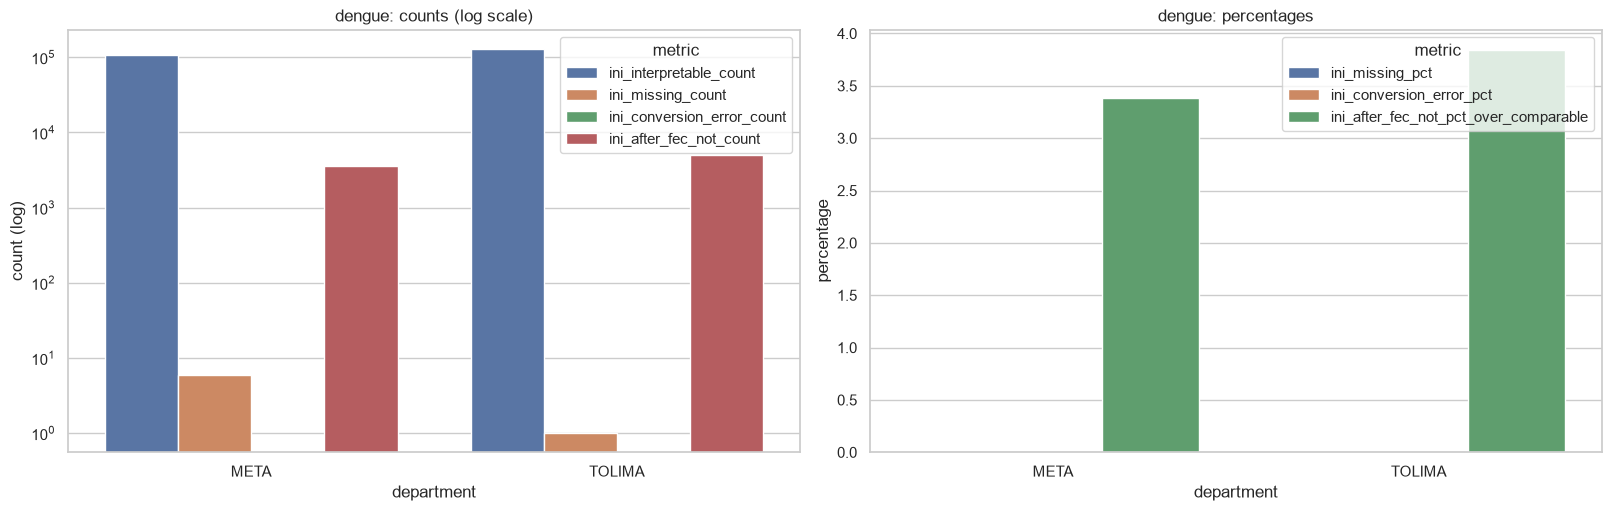

#### Denominators for dengue_grave

,department,records_in_scope,delay_comparable_pairs
2,META,1963,1963
3,TOLIMA,2656,2656


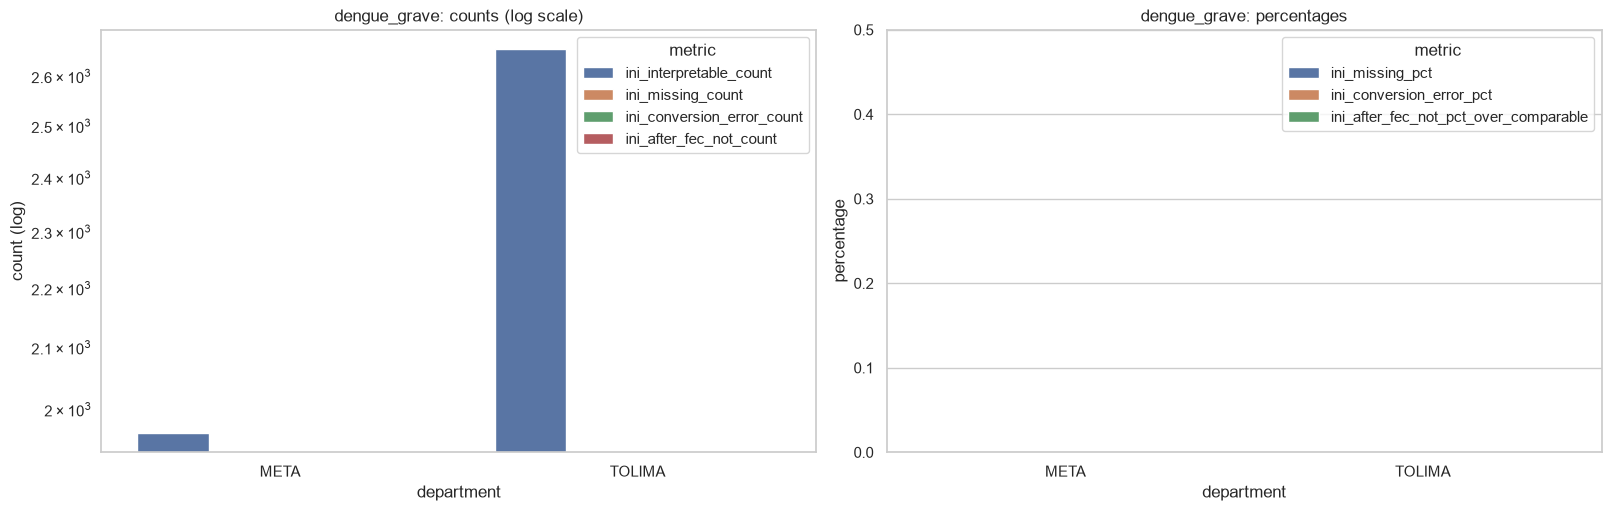

### Monthly interpretable INI_SIN records with explicit discontinuities

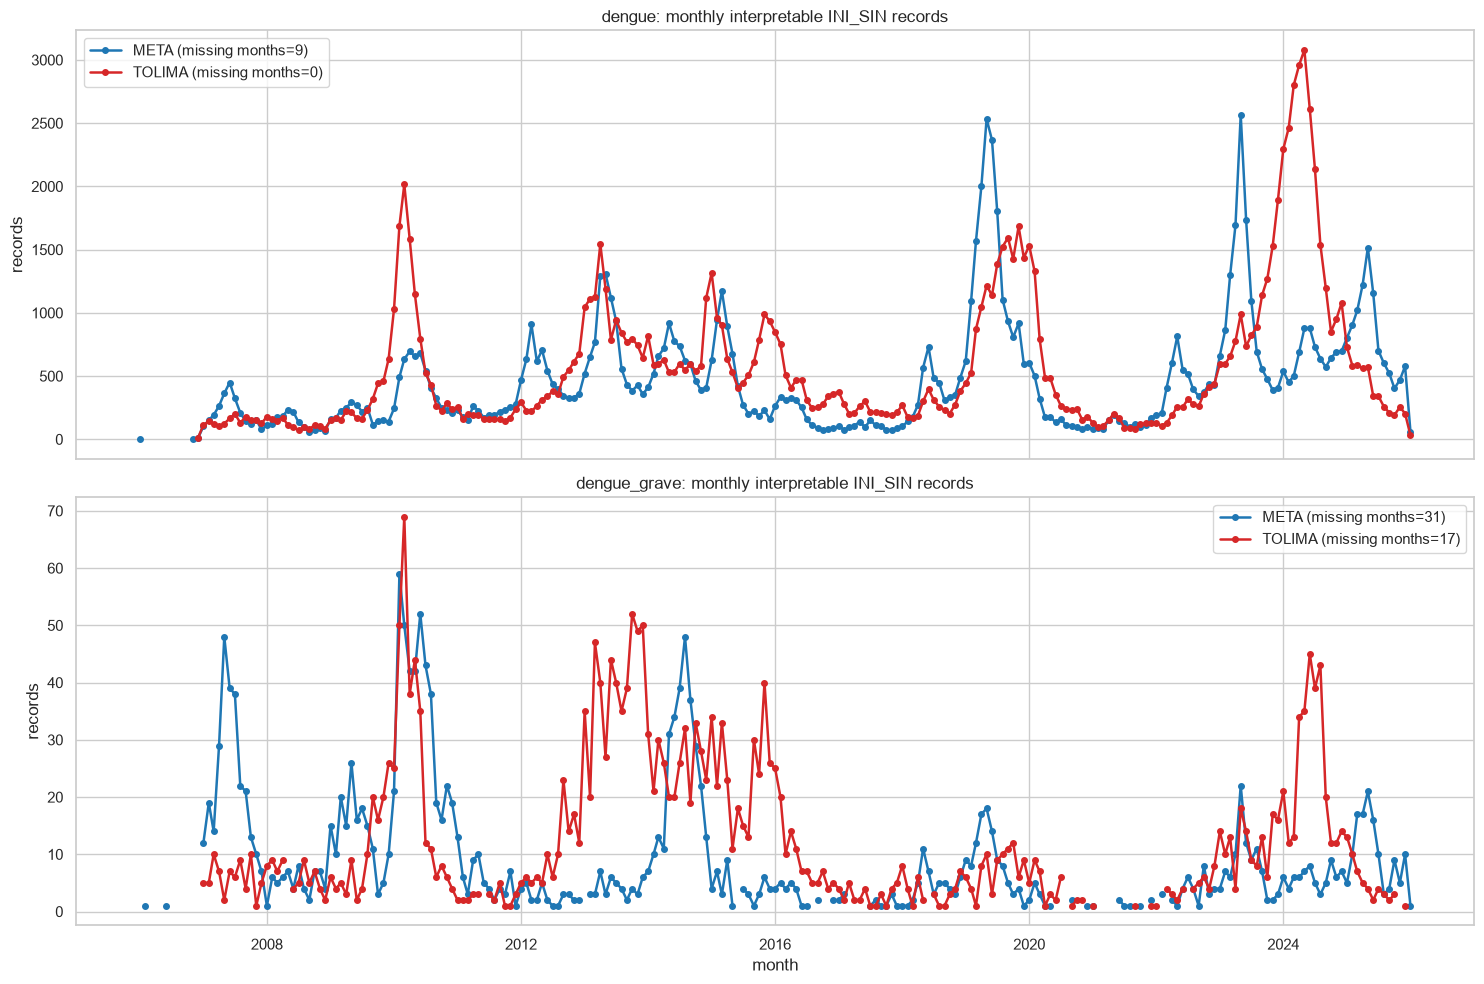

### INI_SIN > FEC_NOT alerts by period (sample highest counts)

,dataset,department,period_ini_month,ini_after_fec_not_count
6,dengue,META,2013-07,497
5,dengue,META,2013-06,486
4,dengue,META,2013-05,435
10,dengue,META,2013-11,367
7,dengue,META,2013-08,358
3,dengue,META,2013-04,331
11,dengue,META,2013-12,310
9,dengue,META,2013-10,306
8,dengue,META,2013-09,305
2,dengue,META,2013-03,124


In [6]:
display(Markdown("### Municipality-level coverage and INI_SIN diagnostics (valid municipality codes only, sample)"))
if not municipal_df.empty:
    municipal_view = municipal_df.copy()
    municipal_view["ini_interpretable_rate"] = (
        municipal_view["records_interpretable_ini_sin"] / municipal_view["records_total"]
    )
    display(
        municipal_view
        .sort_values(["dataset", "department", "records_total"], ascending=[True, True, False])
        .groupby(["dataset", "department"], group_keys=False)
        .head(15)
    )
else:
    display(Markdown("No municipality-level rows available after validated municipality-code filtering."))


display(Markdown("### Temporal distribution of non-interpretable INI_SIN by FEC_NOT month"))
if not temporal_problem_df.empty:
    display(
        temporal_problem_df
        .groupby(["dataset", "department", "problem_status"], as_index=False)["count"]
        .sum()
        .sort_values(["dataset", "department", "problem_status"])
    )
else:
    display(Markdown("No missing/conversion-error INI_SIN rows with interpretable FEC_NOT under current filters."))


# Separate figures for dengue and dengue_grave to avoid cross-file averaging.
for dataset_name in sorted(quality_df["dataset"].unique()):
    ds = quality_df[quality_df["dataset"] == dataset_name].copy()
    if ds.empty:
        continue

    display(Markdown(f"#### Denominators for {dataset_name}"))
    display(ds[["department", "records_in_scope", "delay_comparable_pairs"]])

    fig, axes = plt.subplots(1, 2, figsize=(16, 5), constrained_layout=True)

    counts_plot = ds.melt(
        id_vars=["department"],
        value_vars=[
            "ini_interpretable_count",
            "ini_missing_count",
            "ini_conversion_error_count",
            "ini_after_fec_not_count",
        ],
        var_name="metric",
        value_name="count",
    )

    sns.barplot(
        data=counts_plot,
        x="department",
        y="count",
        hue="metric",
        ax=axes[0],
    )
    axes[0].set_yscale("log")
    axes[0].set_title(f"{dataset_name}: counts (log scale)")
    axes[0].set_ylabel("count (log)")
    axes[0].set_xlabel("department")

    rates_plot = ds.melt(
        id_vars=["department"],
        value_vars=[
            "ini_missing_pct",
            "ini_conversion_error_pct",
            "ini_after_fec_not_pct_over_comparable",
        ],
        var_name="metric",
        value_name="rate",
    )
    rates_plot["rate_pct"] = rates_plot["rate"] * 100

    sns.barplot(
        data=rates_plot,
        x="department",
        y="rate_pct",
        hue="metric",
        ax=axes[1],
    )
    axes[1].set_title(f"{dataset_name}: percentages")
    axes[1].set_ylabel("percentage")
    axes[1].set_xlabel("department")

    if rates_plot["rate_pct"].max() == 0:
        axes[1].set_ylim(0, 0.5)

    plt.show()


if not monthly_df.empty:
    display(Markdown("### Monthly interpretable INI_SIN records with explicit discontinuities"))

    datasets = sorted(monthly_df["dataset"].unique())
    fig, axes = plt.subplots(len(datasets), 1, figsize=(15, 5 * len(datasets)), sharex=True)
    if len(datasets) == 1:
        axes = [axes]

    palette = {"META": "#1f77b4", "TOLIMA": "#d62728"}

    for ax, dataset_name in zip(axes, datasets):
        ds = monthly_df[monthly_df["dataset"] == dataset_name].copy()
        ds["month_period"] = pd.PeriodIndex(ds["month"], freq="M")

        for dept in ["META", "TOLIMA"]:
            dept_ds = ds[ds["department"] == dept].copy()
            if dept_ds.empty:
                continue

            series = dept_ds.set_index("month_period")["records_with_interpretable_ini_sin"].sort_index()
            full_months = pd.period_range(series.index.min(), series.index.max(), freq="M")
            series_reindexed = series.reindex(full_months)

            ax.plot(
                full_months.to_timestamp(),
                series_reindexed.values,
                marker="o",
                linewidth=1.8,
                markersize=4,
                label=f"{dept} (missing months={int(series_reindexed.isna().sum())})",
                color=palette.get(dept),
            )

        ax.set_title(f"{dataset_name}: monthly interpretable INI_SIN records")
        ax.set_ylabel("records")
        ax.legend()

    axes[-1].set_xlabel("month")
    plt.tight_layout()
    plt.show()

if not delay_alert_period_df.empty:
    display(Markdown("### INI_SIN > FEC_NOT alerts by period (sample highest counts)"))
    display(
        delay_alert_period_df
        .sort_values(["dataset", "department", "ini_after_fec_not_count"], ascending=[True, True, False])
        .groupby(["dataset", "department"], group_keys=False)
        .head(12)
    )

In [7]:
import json
import hashlib


OUTPUT_DIR = repo_root / "data" / "interim" / "stage2_divipola_validation"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DIVIPOLA_DEPT_PATH = repo_root / "data" / "sources" / "Divipola-departamentos.md"
DIVIPOLA_MUNI_PATH = repo_root / "data" / "sources" / "Divipola-municipios.md"


def sha256_file(path: Path) -> str:
    h = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()


def load_json_payload(path: Path) -> dict:
    text = path.read_text(encoding="utf-8").strip()
    payload = json.loads(text)
    if not isinstance(payload, dict):
        raise ValueError(f"Top-level JSON payload must be an object in {path}.")
    return payload


def normalize_divipola_name(series: pd.Series) -> pd.Series:
    return normalize_name_series(series).str.replace(r"\s+", " ", regex=True).str.strip()


def parse_divipola_catalogs() -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame, dict]:
    dept_payload = load_json_payload(DIVIPOLA_DEPT_PATH)
    muni_payload = load_json_payload(DIVIPOLA_MUNI_PATH)

    dept_estado = bool(dept_payload.get("estado", False))
    dept_rows = dept_payload.get("resultado", [])
    dept_declared = dept_payload.get("conteo")

    muni_estado = bool(muni_payload.get("estado", False))
    muni_rows = muni_payload.get("resultado", [])
    muni_declared = muni_payload.get("conteo")

    if not isinstance(dept_rows, list):
        raise ValueError("Divipola-departamentos resultado must be a list.")
    if not isinstance(muni_rows, list):
        raise ValueError("Divipola-municipios resultado must be a list.")

    dept_df = pd.DataFrame(dept_rows)
    muni_df = pd.DataFrame(muni_rows)

    required_dept_cols = {"CODIGO_DEPARTAMENTO", "NOMBRE_DEPARTAMENTO"}
    required_muni_cols = {
        "CODIGO_MUNICIPIO",
        "CODIGO_DEPARTAMENTO",
        "CODIGO_DPTO_MPIO",
        "NOMBRE_MUNICIPIO",
    }

    missing_dept_cols = sorted(required_dept_cols.difference(dept_df.columns))
    missing_muni_cols = sorted(required_muni_cols.difference(muni_df.columns))

    if missing_dept_cols:
        raise ValueError(f"Department catalog missing required columns: {missing_dept_cols}")
    if missing_muni_cols:
        raise ValueError(f"Municipality catalog missing required columns: {missing_muni_cols}")

    dept_df = dept_df.copy()
    dept_df["department_code"] = normalize_text_series(dept_df["CODIGO_DEPARTAMENTO"]).str.zfill(2)
    dept_df["department_name"] = normalize_divipola_name(dept_df["NOMBRE_DEPARTAMENTO"])

    muni_df = muni_df.copy()
    muni_df["department_code"] = normalize_text_series(muni_df["CODIGO_DEPARTAMENTO"]).str.zfill(2)
    muni_df["municipality_code"] = normalize_text_series(muni_df["CODIGO_MUNICIPIO"]).str.zfill(3)
    muni_df["municipality_code_full"] = normalize_text_series(muni_df["CODIGO_DPTO_MPIO"]).str.zfill(5)
    muni_df["municipality_name"] = normalize_divipola_name(muni_df["NOMBRE_MUNICIPIO"])

    dept_target = dept_df[dept_df["department_code"].isin(TARGET_DPTO_CODES.keys())].copy()
    dept_target = dept_target[["department_code", "department_name"]].drop_duplicates()

    muni_target = muni_df[muni_df["department_code"].isin(TARGET_DPTO_CODES.keys())].copy()
    muni_target = muni_target[["department_code", "municipality_code", "municipality_code_full", "municipality_name"]].drop_duplicates()

    dept_map = dept_df[["department_code", "department_name"]].drop_duplicates().set_index("department_code")["department_name"]
    muni_target["department_name"] = muni_target["department_code"].map(dept_map)

    # Cross-catalog consistency checks.
    muni_target["prefix_matches_department"] = muni_target["municipality_code_full"].str[:2].eq(muni_target["department_code"])
    municipality_code_duplicates = muni_target["municipality_code_full"].duplicated(keep=False)

    validation_rows = [
        {
            "check": "department_json_estado_true",
            "state": "PASS" if dept_estado else "FAIL",
            "value": dept_estado,
            "details": "Top-level estado from Divipola-departamentos payload",
        },
        {
            "check": "municipality_json_estado_true",
            "state": "PASS" if muni_estado else "FAIL",
            "value": muni_estado,
            "details": "Top-level estado from Divipola-municipios payload",
        },
        {
            "check": "department_declared_count_matches_rows",
            "state": "PASS" if (dept_declared is None or int(dept_declared) == len(dept_df)) else "FAIL",
            "value": dept_declared,
            "details": f"declared={dept_declared}, rows={len(dept_df)}",
        },
        {
            "check": "municipality_declared_count_matches_rows",
            "state": "PASS" if (muni_declared is None or int(muni_declared) == len(muni_df)) else "FAIL",
            "value": muni_declared,
            "details": f"declared={muni_declared}, rows={len(muni_df)}",
        },
        {
            "check": "municipality_prefix_matches_department_code",
            "state": "PASS" if bool(muni_target["prefix_matches_department"].all()) else "FAIL",
            "value": int((~muni_target["prefix_matches_department"]).sum()),
            "details": "Count of municipality rows where CODIGO_DPTO_MPIO prefix does not match CODIGO_DEPARTAMENTO",
        },
        {
            "check": "municipality_code_full_duplicates",
            "state": "FAIL" if bool(municipality_code_duplicates.any()) else "PASS",
            "value": int(municipality_code_duplicates.sum()),
            "details": "Count of duplicated CODIGO_DPTO_MPIO values in target departments",
        },
        {
            "check": "department_name_missing_values",
            "state": "FAIL" if bool(dept_target["department_name"].eq("").any()) else "PASS",
            "value": int(dept_target["department_name"].eq("").sum()),
            "details": "Blank normalized department names in target departments",
        },
        {
            "check": "municipality_name_missing_values",
            "state": "FAIL" if bool(muni_target["municipality_name"].eq("").any()) else "PASS",
            "value": int(muni_target["municipality_name"].eq("").sum()),
            "details": "Blank normalized municipality names in target departments",
        },
    ]

    counts_df = (
        muni_target
        .groupby(["department_code", "department_name"], as_index=False)
        .agg(municipality_count=("municipality_code_full", "nunique"))
        .sort_values(["department_code"], ignore_index=True)
    )

    source_metadata = load_json_payload(repo_root / "data" / "sources" / "divipola-provenance.json")
    for name, path in [(DIVIPOLA_DEPT_PATH.name, DIVIPOLA_DEPT_PATH), (DIVIPOLA_MUNI_PATH.name, DIVIPOLA_MUNI_PATH)]:
        entry = source_metadata["files"][name]
        if sha256_file(path) != entry["sha256"]:
            raise ValueError(f"Catalog hash no longer matches recorded provenance: {name}")
        if not entry["source_url"].startswith("https://geoportal.dane.gov.co/"):
            raise ValueError(f"Missing DANE source URL: {name}")
    for key in ["download_date", "reported_version_date", "metadata_basis"]:
        if not source_metadata.get(key):
            raise ValueError(f"Missing supplied provenance field: {key}")
    validation_rows.append({
        "check": "supplied_provenance_recorded_and_hash_bound", "state": "PASS", "value": True,
        "details": "Human-supplied URL/download/version recorded and catalog hashes matched; publication version not independently verified.",
    })

    metadata = {
        "generated_at": pd.Timestamp.now(tz=ZoneInfo(EXECUTION_TIMEZONE)).isoformat(),
        "execution_timezone": EXECUTION_TIMEZONE,
        "files": {
            "Divipola-departamentos.md": {
                "relative_path": str(DIVIPOLA_DEPT_PATH.relative_to(repo_root)),
                "sha256": sha256_file(DIVIPOLA_DEPT_PATH),
                "size_bytes": DIVIPOLA_DEPT_PATH.stat().st_size,
                "modified_local": pd.Timestamp(DIVIPOLA_DEPT_PATH.stat().st_mtime, unit="s").tz_localize("UTC").tz_convert(EXECUTION_TIMEZONE).isoformat(),
                "declared_conteo": dept_declared,
                "rows_resultado": len(dept_df),
                "estado": dept_estado,
            },
            "Divipola-municipios.md": {
                "relative_path": str(DIVIPOLA_MUNI_PATH.relative_to(repo_root)),
                "sha256": sha256_file(DIVIPOLA_MUNI_PATH),
                "size_bytes": DIVIPOLA_MUNI_PATH.stat().st_size,
                "modified_local": pd.Timestamp(DIVIPOLA_MUNI_PATH.stat().st_mtime, unit="s").tz_localize("UTC").tz_convert(EXECUTION_TIMEZONE).isoformat(),
                "declared_conteo": muni_declared,
                "rows_resultado": len(muni_df),
                "estado": muni_estado,
            },
        },
        "source_metadata": source_metadata,
    }

    return dept_target, muni_target, pd.DataFrame(validation_rows), metadata, counts_df


TARGET_DEPT_TARGET_DF, TARGET_MUNI_TARGET_DF, DIVIPOLA_VALIDATION_DF, DIVIPOLA_METADATA, DIVIPOLA_COUNTS_DF = parse_divipola_catalogs()
EXPECTED_DIVIPOLA_CODES = set(TARGET_MUNI_TARGET_DF["municipality_code_full"].tolist())


display(Markdown("### DIVIPOLA catalog structure and supplied provenance"))
display(DIVIPOLA_VALIDATION_DF)
display(DIVIPOLA_COUNTS_DF)
print("Download:", DIVIPOLA_METADATA["source_metadata"]["download_date"],
      "Reported version:", DIVIPOLA_METADATA["source_metadata"]["reported_version_date"])
print("Metadata supplied by Mauricio; historical applicability and independent publication-version verification remain separate.")


### DIVIPOLA catalog structure and supplied provenance

,check,state,value,details
0,department_json_estado_true,PASS,True,Top-level estado from Divipola-departamentos p...
1,municipality_json_estado_true,PASS,True,Top-level estado from Divipola-municipios payload
2,department_declared_count_matches_rows,PASS,None,"declared=None, rows=33"
3,municipality_declared_count_matches_rows,PASS,1122,"declared=1122, rows=1122"
4,municipality_prefix_matches_department_code,PASS,0,Count of municipality rows where CODIGO_DPTO_M...
5,municipality_code_full_duplicates,PASS,0,Count of duplicated CODIGO_DPTO_MPIO values in...
6,department_name_missing_values,PASS,0,Blank normalized department names in target de...
7,municipality_name_missing_values,PASS,0,Blank normalized municipality names in target ...
8,supplied_provenance_recorded_and_hash_bound,PASS,True,Human-supplied URL/download/version recorded a...


,department_code,department_name,municipality_count
0,50,META,29
1,73,TOLIMA,47


Download: 2026-10-16 Reported version: 2026-09-30
Metadata supplied by Mauricio; historical applicability and independent publication-version verification remain separate.


In [8]:
def analyze_climate_file(
    path: Path,
    expected_catalog_df: pd.DataFrame,
    epi_window_start: pd.Timestamp | pd.NaT,
    epi_window_end: pd.Timestamp | pd.NaT,
    chunk_size: int = 250_000,
):
    expected_catalog = expected_catalog_df[["department", "municipality_code_full"]].drop_duplicates().copy()
    expected_set = set(expected_catalog["municipality_code_full"].tolist())

    stats = Counter()
    variable_missing = Counter()
    variable_zero = Counter()
    duplicate_key_counter = Counter()
    municipality_gap_sets: dict[str, set] = {}

    muni_state = defaultdict(
        lambda: {
            "department": None,
            "municipality_name": None,
            "rows": 0,
            "rows_valid_date": 0,
            "rows_date_missing": 0,
            "rows_date_invalid": 0,
            "valid_dates": set(),
            "min_date": None,
            "max_date": None,
            "rows_all_climate_missing": 0,
        }
    )

    target_dept_map = TARGET_DPTO_CODES

    global_min_date = None
    global_max_date = None
    climate_observed_codes = set()

    reader = pd.read_csv(
        path,
        usecols=CLIMATE_USECOLS,
        dtype=str,
        chunksize=chunk_size,
        low_memory=True,
    )

    for chunk in reader:
        stats["rows_total"] += len(chunk)

        dept_code_info = classify_numeric_code(
            chunk["dpto_ccdgo"],
            expected_len=2,
            allow_left_pad=True,
            unknown_codes={"00"},
        )
        mun_code_info = classify_numeric_code(
            chunk["mpio_cdpmp"],
            expected_len=5,
            allow_left_pad=True,
            unknown_codes={"00000"},
        )
        dept_name_info = classify_department_name(chunk["dpto_cnmbr"])
        mun_name_norm = normalize_name_series(chunk["mpio_cnmbr"])

        dept_code_valid = dept_code_info["status"].eq("valid")
        dept_code = dept_code_info["normalized"]
        dept_in_scope_by_code = dept_code_valid & dept_code.isin(target_dept_map.keys())

        dept_name_target = dept_name_info["name_class"].eq("target")
        dept_name_to_code = dept_name_info["normalized"].map(TARGET_DPTO_NAME_TO_CODE).fillna("")
        dept_code_name_conflict = dept_in_scope_by_code & dept_name_target & dept_name_to_code.ne(dept_code)

        stats["rows_target_department_by_code"] += int(dept_in_scope_by_code.sum())
        stats["rows_target_name_without_valid_code"] += int((~dept_code_valid & dept_name_target).sum())
        stats["rows_target_department_code_name_conflict"] += int(dept_code_name_conflict.sum())

        target_df = pd.DataFrame(
            {
                "department_code": dept_code,
                "department_label": dept_code.map(target_dept_map),
                "municipality_code": mun_code_info["normalized"],
                "municipality_code_status": mun_code_info["status"],
                "municipality_name": mun_name_norm,
                "date_raw": normalize_text_series(chunk["date"]),
            }
        )
        for var in CLIMATE_VARS:
            target_df[var] = normalize_text_series(chunk[var])

        target_df = target_df[dept_in_scope_by_code].copy()
        if target_df.empty:
            continue

        stats["rows_target_with_missing_municipality_code"] += int(target_df["municipality_code_status"].eq("missing").sum())
        stats["rows_target_with_unknown_municipality_code"] += int(
            (target_df["municipality_code_status"].eq("unknown") | target_df["municipality_code"].eq("00000")).sum()
        )
        stats["rows_target_with_invalid_municipality_code"] += int(
            target_df["municipality_code_status"].isin(["invalid_length", "invalid_chars"]).sum()
        )

        valid_municipality_mask = target_df["municipality_code_status"].eq("valid") & target_df["municipality_code"].ne("00000")
        stats["rows_target_with_valid_municipality_code"] += int(valid_municipality_mask.sum())

        climate_observed_codes.update(target_df.loc[valid_municipality_mask, "municipality_code"].unique().tolist())

        date_series = target_df["date_raw"]
        date_dt = pd.to_datetime(date_series, format="%Y-%m-%d", errors="coerce")
        date_missing = date_series.eq("") | date_series.str.lower().isin({"nan", "none", "nat"})
        date_invalid = (~date_missing) & date_dt.isna()
        date_valid = date_dt.notna()

        stats["rows_target_date_missing"] += int(date_missing.sum())
        stats["rows_target_date_invalid"] += int(date_invalid.sum())
        stats["rows_target_date_interpretable"] += int(date_valid.sum())

        for var in CLIMATE_VARS:
            var_s = target_df[var]
            missing_mask = var_s.eq("")
            numeric = pd.to_numeric(var_s, errors="coerce")
            zero_mask = (~missing_mask) & numeric.eq(0)
            variable_missing[var] += int(missing_mask.sum())
            variable_zero[var] += int(zero_mask.sum())

        all_missing_mask = np.ones(len(target_df), dtype=bool)
        for var in CLIMATE_VARS:
            all_missing_mask &= target_df[var].eq("").to_numpy()
        stats["rows_target_all_climate_missing"] += int(all_missing_mask.sum())

        target_df["date_dt"] = date_dt
        target_df["date_missing"] = date_missing
        target_df["date_invalid"] = date_invalid
        target_df["all_climate_missing"] = all_missing_mask

        valid_rows = target_df[valid_municipality_mask].copy()
        if valid_rows.empty:
            continue

        for row in valid_rows.itertuples(index=False):
            key = row.municipality_code
            state = muni_state[key]
            state["department"] = row.department_label
            if state["municipality_name"] in {None, "", "NAN", "NONE", "NAT"} and row.municipality_name not in {"", "NAN", "NONE", "NAT"}:
                state["municipality_name"] = row.municipality_name
            state["rows"] += 1

            if row.date_missing:
                state["rows_date_missing"] += 1
            elif row.date_invalid:
                state["rows_date_invalid"] += 1
            else:
                state["rows_valid_date"] += 1
                state["valid_dates"].add(row.date_dt.date())
                state["min_date"] = row.date_dt if state["min_date"] is None else min(state["min_date"], row.date_dt)
                state["max_date"] = row.date_dt if state["max_date"] is None else max(state["max_date"], row.date_dt)
                duplicate_key_counter[(row.municipality_code, row.date_dt.date())] += 1

            state["rows_all_climate_missing"] += int(row.all_climate_missing)

        local_valid_dates = valid_rows.loc[valid_rows["date_dt"].notna(), "date_dt"]
        if not local_valid_dates.empty:
            local_min = local_valid_dates.min()
            local_max = local_valid_dates.max()
            global_min_date = local_min if global_min_date is None else min(global_min_date, local_min)
            global_max_date = local_max if global_max_date is None else max(global_max_date, local_max)

    if pd.notna(epi_window_start) and pd.notna(epi_window_end):
        epi_start = pd.Timestamp(epi_window_start)
        epi_end = pd.Timestamp(epi_window_end)
    else:
        epi_start = pd.NaT
        epi_end = pd.NaT

    climate_start = pd.Timestamp(global_min_date) if global_min_date is not None else pd.NaT
    climate_end = pd.Timestamp(global_max_date) if global_max_date is not None else pd.NaT

    if pd.notna(epi_start) and pd.notna(epi_end) and pd.notna(climate_start) and pd.notna(climate_end):
        overlap_start = max(epi_start, climate_start)
        overlap_end = min(epi_end, climate_end)
        if overlap_start <= overlap_end:
            overlap_dates = pd.date_range(overlap_start, overlap_end, freq="D")
        else:
            overlap_start = pd.NaT
            overlap_end = pd.NaT
            overlap_dates = pd.DatetimeIndex([])
    else:
        overlap_start = pd.NaT
        overlap_end = pd.NaT
        overlap_dates = pd.DatetimeIndex([])

    overlap_date_set = set(overlap_dates.date)

    all_codes = sorted(expected_set | climate_observed_codes)
    coverage_rows = []

    for code in all_codes:
        state = muni_state.get(code)

        expected_in_epi = code in expected_set
        observed_in_climate = code in climate_observed_codes

        if state is None:
            dept = TARGET_DPTO_CODES.get(code[:2], "UNKNOWN")
            municipality_name = ""
            rows = 0
            date_min = pd.NaT
            date_max = pd.NaT
            unique_dates = 0
            rows_date_missing = 0
            rows_date_invalid = 0
            rows_all_missing = 0
            valid_dates = set()
        else:
            dept = state["department"]
            municipality_name = state["municipality_name"]
            rows = state["rows"]
            date_min = state["min_date"]
            date_max = state["max_date"]
            unique_dates = len(state["valid_dates"])
            rows_date_missing = state["rows_date_missing"]
            rows_date_invalid = state["rows_date_invalid"]
            rows_all_missing = state["rows_all_climate_missing"]
            valid_dates = state["valid_dates"]

        if overlap_date_set:
            missing_dates = sorted(overlap_date_set.difference(valid_dates))
            missing_dates_count = len(missing_dates)
            missing_dates_sample = ", ".join(str(d) for d in missing_dates[:10])
        else:
            missing_dates = []
            missing_dates_count = np.nan
            missing_dates_sample = ""

        municipality_gap_sets[code] = set(missing_dates)

        if expected_in_epi and observed_in_climate:
            coverage_status = "both"
        elif expected_in_epi and (not observed_in_climate):
            coverage_status = "expected_only"
        elif (not expected_in_epi) and observed_in_climate:
            coverage_status = "climate_only"
        else:
            coverage_status = "unreachable"

        coverage_rows.append(
            {
                "department": dept,
                "municipality_code_full": code,
                "municipality_name": municipality_name,
                "expected_in_inventory": expected_in_epi,
                "observed_in_climate": observed_in_climate,
                "coverage_status": coverage_status,
                "rows": rows,
                "rows_date_missing": rows_date_missing,
                "rows_date_invalid": rows_date_invalid,
                "date_min": date_min,
                "date_max": date_max,
                "unique_dates": unique_dates,
                "missing_dates_in_overlap_window": missing_dates_count,
                "missing_dates_sample": missing_dates_sample,
                "rows_all_climate_missing": rows_all_missing,
                "rows_all_climate_missing_pct": (rows_all_missing / rows) if rows else np.nan,
            }
        )

    coverage_df = pd.DataFrame(coverage_rows)
    if not coverage_df.empty:
        coverage_df = coverage_df.sort_values(["department", "municipality_code_full"], ignore_index=True)

    expected_without_climate = sorted(expected_set.difference(climate_observed_codes))
    climate_without_epi = sorted(climate_observed_codes.difference(expected_set))

    gap_freq_counter = Counter()
    for code in expected_set:
        for d in municipality_gap_sets.get(code, set()):
            gap_freq_counter[d] += 1

    gap_freq_rows = [
        {
            "date": pd.Timestamp(date_val),
            "municipality_count_missing_date": count,
            "missing_pct_over_expected_municipalities": count / len(expected_set) if expected_set else np.nan,
        }
        for date_val, count in sorted(gap_freq_counter.items())
    ]
    gap_freq_df = pd.DataFrame(gap_freq_rows)

    expected_gap_sets = [municipality_gap_sets.get(code, set()) for code in expected_set]
    if expected_gap_sets:
        common_missing_dates = set.intersection(*expected_gap_sets)
        unique_gap_pattern_count = len({frozenset(s) for s in expected_gap_sets})
        all_share_same_pattern = unique_gap_pattern_count == 1
    else:
        common_missing_dates = set()
        unique_gap_pattern_count = np.nan
        all_share_same_pattern = np.nan

    gap_pattern_summary_df = pd.DataFrame(
        [
            {
                "expected_municipality_count": len(expected_set),
                "overlap_days": len(overlap_date_set),
                "municipalities_fully_absent_in_climate": len(expected_without_climate),
                "all_municipalities_share_same_missing_dates": all_share_same_pattern,
                "unique_gap_pattern_count": unique_gap_pattern_count,
                "common_missing_dates_count": len(common_missing_dates),
                "common_missing_dates_sample": ", ".join(str(d) for d in sorted(common_missing_dates)[:10]),
            }
        ]
    )

    duplicate_rows = sum(1 for _, count in duplicate_key_counter.items() if count > 1)
    duplicate_extra_rows = sum((count - 1) for count in duplicate_key_counter.values() if count > 1)

    variable_quality_df = pd.DataFrame(
        {
            "variable": CLIMATE_VARS,
            "missing_count": [variable_missing[v] for v in CLIMATE_VARS],
            "zero_count": [variable_zero[v] for v in CLIMATE_VARS],
            "rows_target_department_by_code": stats["rows_target_department_by_code"],
        }
    )
    variable_quality_df["missing_pct"] = variable_quality_df["missing_count"] / variable_quality_df["rows_target_department_by_code"]
    variable_quality_df["zero_pct"] = variable_quality_df["zero_count"] / variable_quality_df["rows_target_department_by_code"]

    summary_df = pd.DataFrame(
        [
            {
                "rows_total": stats["rows_total"],
                "rows_target_department_by_code": stats["rows_target_department_by_code"],
                "rows_target_name_without_valid_code": stats["rows_target_name_without_valid_code"],
                "rows_target_department_code_name_conflict": stats["rows_target_department_code_name_conflict"],
                "rows_target_with_valid_municipality_code": stats["rows_target_with_valid_municipality_code"],
                "rows_target_with_missing_municipality_code": stats["rows_target_with_missing_municipality_code"],
                "rows_target_with_unknown_municipality_code": stats["rows_target_with_unknown_municipality_code"],
                "rows_target_with_invalid_municipality_code": stats["rows_target_with_invalid_municipality_code"],
                "rows_target_date_interpretable": stats["rows_target_date_interpretable"],
                "rows_target_date_missing": stats["rows_target_date_missing"],
                "rows_target_date_invalid": stats["rows_target_date_invalid"],
                "rows_target_all_climate_missing": stats["rows_target_all_climate_missing"],
                "duplicate_municipality_date_values": duplicate_rows,
                "duplicate_extra_rows": duplicate_extra_rows,
                "epi_window_start": epi_start,
                "epi_window_end": epi_end,
                "climate_window_start": climate_start,
                "climate_window_end": climate_end,
                "overlap_start": overlap_start,
                "overlap_end": overlap_end,
                "overlap_days": len(overlap_date_set),
                "expected_municipalities_from_divipola": len(expected_set),
                "observed_municipalities_in_climate": len(climate_observed_codes),
                "expected_without_climate": len(expected_without_climate),
                "climate_without_epi": len(climate_without_epi),
            }
        ]
    )

    homologation_df = pd.DataFrame(
        [
            {
                "type": "expected_without_climate",
                "count": len(expected_without_climate),
                "sample_codes": ", ".join(expected_without_climate[:15]),
            },
            {
                "type": "climate_without_epi",
                "count": len(climate_without_epi),
                "sample_codes": ", ".join(climate_without_epi[:15]),
            },
        ]
    )

    return {
        "summary_df": summary_df,
        "variable_quality_df": variable_quality_df,
        "coverage_df": coverage_df,
        "gap_pattern_summary_df": gap_pattern_summary_df,
        "gap_freq_df": gap_freq_df,
        "homologation_df": homologation_df,
        "expected_set": expected_set,
        "climate_observed_codes": climate_observed_codes,
    }


climate_outputs = analyze_climate_file(
    data_paths["climate"],
    expected_catalog_df=TARGET_MUNI_TARGET_DF[["department_name", "municipality_code_full"]].rename(columns={"department_name": "department"}),
    epi_window_start=epi_union_window_start,
    epi_window_end=epi_union_window_end,
)

climate_summary_df = climate_outputs["summary_df"]
climate_variable_quality_df = climate_outputs["variable_quality_df"]
climate_coverage_df = climate_outputs["coverage_df"]
climate_gap_pattern_summary_df = climate_outputs["gap_pattern_summary_df"]
climate_gap_freq_df = climate_outputs["gap_freq_df"]
climate_homologation_df = climate_outputs["homologation_df"]


display(Markdown("### Climate coverage summary (Tolima/Meta by DIVIPOLA expected municipalities)"))
display(climate_summary_df)

display(Markdown("### Climate variable missingness and zero-value profile"))
display(climate_variable_quality_df)

display(Markdown("### Municipality coverage and overlap gaps (sample)"))
if not climate_coverage_df.empty:
    display(
        climate_coverage_df
        .sort_values(["coverage_status", "department", "missing_dates_in_overlap_window"], ascending=[True, True, False])
        .head(60)
    )
else:
    display(Markdown("No climate municipality coverage rows were generated."))

display(Markdown("### Homologation and unmatched-code diagnostics"))
display(climate_homologation_df)

display(Markdown("### Missing-date pattern summary across expected municipalities"))
display(climate_gap_pattern_summary_df)

if not climate_gap_freq_df.empty:
    display(Markdown("### Most frequent missing dates across expected municipalities (sample)"))
    display(climate_gap_freq_df.sort_values("municipality_count_missing_date", ascending=False).head(25))

### Climate coverage summary (Tolima/Meta by DIVIPOLA expected municipalities)

,rows_total,rows_target_department_by_code,rows_target_name_without_valid_code,rows_target_department_code_name_conflict,rows_target_with_valid_municipality_code,rows_target_with_missing_municipality_code,rows_target_with_unknown_municipality_code,rows_target_with_invalid_municipality_code,rows_target_date_interpretable,rows_target_date_missing,rows_target_date_invalid,rows_target_all_climate_missing,duplicate_municipality_date_values,duplicate_extra_rows,epi_window_start,epi_window_end,climate_window_start,climate_window_end,overlap_start,overlap_end,overlap_days,expected_municipalities_from_divipola,observed_municipalities_in_climate,expected_without_climate,climate_without_epi
0,7751898,525084,0,0,525084,0,0,0,525084,0,0,0,0,0,2006-01-20,2026-01-03,2007-01-01,2025-12-31,2007-01-01,2025-12-31,6940,76,76,0,0


### Climate variable missingness and zero-value profile

,variable,missing_count,zero_count,rows_target_department_by_code,missing_pct,zero_pct
0,rain_mm_day,0,234638,525084,0.0,0.446858
1,temp_mean_c,0,0,525084,0.0,0.000000
2,dewpoint_mean_c,0,0,525084,0.0,0.000000
3,soil_water_l1_mean,0,0,525084,0.0,0.000000
4,surface_runoff_mm_day,0,2751,525084,0.0,0.005239
5,total_evaporation_mm_day_ecmwf,0,0,525084,0.0,0.000000
6,wind_u_mean_ms,0,0,525084,0.0,0.000000
7,wind_v_mean_ms,0,0,525084,0.0,0.000000
8,solar_radiation_mj_m2_day,0,0,525084,0.0,0.000000


### Municipality coverage and overlap gaps (sample)

...

,type,count,sample_codes
0,expected_without_climate,0,
1,climate_without_epi,0,


### Missing-date pattern summary across expected municipalities

,expected_municipality_count,overlap_days,municipalities_fully_absent_in_climate,all_municipalities_share_same_missing_dates,unique_gap_pattern_count,common_missing_dates_count,common_missing_dates_sample
0,76,6940,0,True,1,31,"2020-01-01, 2020-01-02, 2020-01-03, 2020-01-04..."


### Most frequent missing dates across expected municipalities (sample)

,date,municipality_count_missing_date,missing_pct_over_expected_municipalities
0,2020-01-01,76,1.0
16,2020-01-17,76,1.0
29,2020-01-30,76,1.0
28,2020-01-29,76,1.0
27,2020-01-28,76,1.0
26,2020-01-27,76,1.0
25,2020-01-26,76,1.0
24,2020-01-25,76,1.0
23,2020-01-24,76,1.0
22,2020-01-23,76,1.0


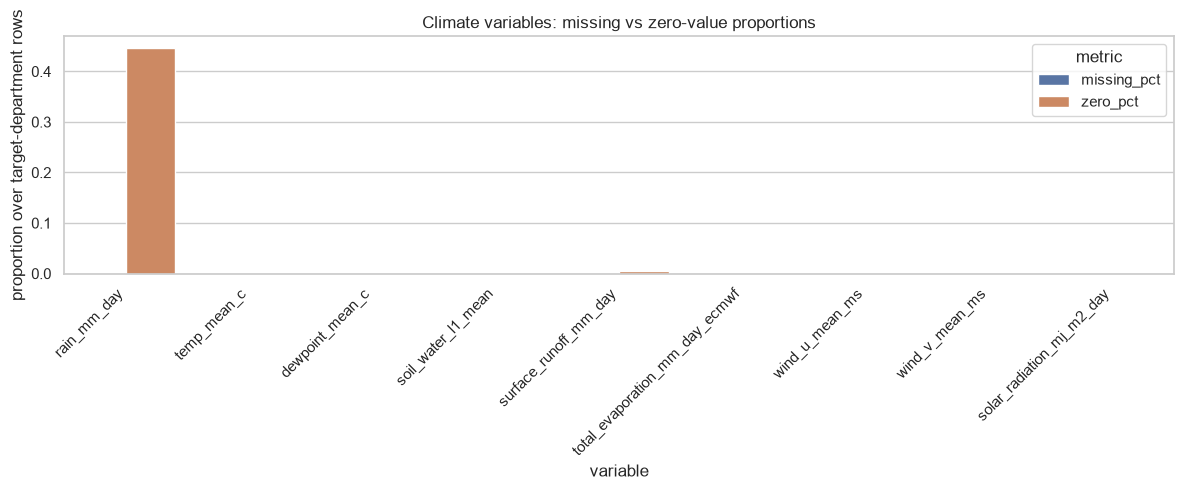

### Expected municipalities with highest missing-date counts (sample)

,department,municipality_code_full,municipality_name,observed_in_climate,missing_dates_in_overlap_window,missing_dates_sample
0,META,50001,VILLAVICENCIO,True,31,"2020-01-01, 2020-01-02, 2020-01-03, 2020-01-04..."
1,META,50006,ACACIAS,True,31,"2020-01-01, 2020-01-02, 2020-01-03, 2020-01-04..."
2,META,50110,BARRANCA DE UPIA,True,31,"2020-01-01, 2020-01-02, 2020-01-03, 2020-01-04..."
3,META,50124,CABUYARO,True,31,"2020-01-01, 2020-01-02, 2020-01-03, 2020-01-04..."
4,META,50150,CASTILLA LA NUEVA,True,31,"2020-01-01, 2020-01-02, 2020-01-03, 2020-01-04..."
5,META,50223,CUBARRAL,True,31,"2020-01-01, 2020-01-02, 2020-01-03, 2020-01-04..."
6,META,50226,CUMARAL,True,31,"2020-01-01, 2020-01-02, 2020-01-03, 2020-01-04..."
7,META,50245,EL CALVARIO,True,31,"2020-01-01, 2020-01-02, 2020-01-03, 2020-01-04..."
8,META,50251,EL CASTILLO,True,31,"2020-01-01, 2020-01-02, 2020-01-03, 2020-01-04..."
9,META,50270,EL DORADO,True,31,"2020-01-01, 2020-01-02, 2020-01-03, 2020-01-04..."


### Expected municipalities completely absent in climate

,department,municipality_code_full,municipality_name,coverage_status


### Coverage checks status

,check,state,details
0,Official municipality inventory completeness b...,PASS,"DIVIPOLA catalogs parsed, validated and bound ..."
1,Expected municipalities are not restricted to ...,PASS,Expected set built independently from validate...
2,Explicit source windows and intersection window,PASS,Epi/climate windows and overlap were computed ...
3,"Missing-date counts are computed, not hardcoded",PASS,Maximum missing dates over expected municipali...
4,Gap-pattern comparison across municipalities,PASS,"all_share_same_pattern=True, unique_gap_patter..."
5,No automatic INI_SIN substitution by FEC_NOT,PASS,INI_SIN and FEC_NOT are analyzed separately; n...


In [9]:
if not climate_variable_quality_df.empty:
    clim_plot = climate_variable_quality_df.copy()
    clim_plot = clim_plot.melt(
        id_vars=["variable"],
        value_vars=["missing_pct", "zero_pct"],
        var_name="metric",
        value_name="value",
    )

    plt.figure(figsize=(12, 5))
    sns.barplot(data=clim_plot, x="variable", y="value", hue="metric")
    plt.xticks(rotation=45, ha="right")
    plt.ylabel("proportion over target-department rows")
    plt.title("Climate variables: missing vs zero-value proportions")
    plt.tight_layout()
    plt.show()

if not climate_coverage_df.empty:
    expected_cov = climate_coverage_df[climate_coverage_df["expected_in_inventory"]].copy()

    if not expected_cov.empty:
        top_missing = (
            expected_cov
            .sort_values(["department", "missing_dates_in_overlap_window"], ascending=[True, False])
            .groupby("department", group_keys=False)
            .head(15)
            [["department", "municipality_code_full", "municipality_name", "observed_in_climate", "missing_dates_in_overlap_window", "missing_dates_sample"]]
        )
        display(Markdown("### Expected municipalities with highest missing-date counts (sample)"))
        display(top_missing)

        absent_expected = expected_cov[~expected_cov["observed_in_climate"]][
            ["department", "municipality_code_full", "municipality_name", "coverage_status"]
        ]
        display(Markdown("### Expected municipalities completely absent in climate"))
        display(absent_expected.head(50))

max_missing_dates = np.nan
if not climate_coverage_df.empty:
    exp_cov = climate_coverage_df[climate_coverage_df["expected_in_inventory"]]
    if not exp_cov.empty:
        max_missing_dates = exp_cov["missing_dates_in_overlap_window"].max()

same_gap_pattern = climate_gap_pattern_summary_df.loc[0, "all_municipalities_share_same_missing_dates"]
unique_gap_patterns = climate_gap_pattern_summary_df.loc[0, "unique_gap_pattern_count"]
common_missing_count = climate_gap_pattern_summary_df.loc[0, "common_missing_dates_count"]

inventory_state = "PASS" if DIVIPOLA_VALIDATION_DF["state"].eq("PASS").all() else "FAIL"
overlap_days = int(climate_summary_df.loc[0, "overlap_days"]) if not climate_summary_df.empty else 0

coverage_checks = pd.DataFrame(
    [
        {
            "check": "Official municipality inventory completeness baseline",
            "state": inventory_state,
            "details": "DIVIPOLA catalogs parsed, validated and bound to supplied provenance; see catalog validation table.",
        },
        {
            "check": "Expected municipalities are not restricted to INI_SIN-interpretable rows",
            "state": "PASS",
            "details": f"Expected set built independently from validated DIVIPOLA target-department codes (count={len(climate_outputs['expected_set'])}).",
        },
        {
            "check": "Explicit source windows and intersection window",
            "state": "PASS" if overlap_days > 0 else "BLOCKED",
            "details": f"Epi/climate windows and overlap were computed explicitly; overlap_days={overlap_days}.",
        },
        {
            "check": "Missing-date counts are computed, not hardcoded",
            "state": "PASS" if pd.notna(max_missing_dates) else "UNVERIFIED",
            "details": f"Maximum missing dates over expected municipalities in overlap window: {max_missing_dates}.",
        },
        {
            "check": "Gap-pattern comparison across municipalities",
            "state": "PASS",
            "details": (
                f"all_share_same_pattern={same_gap_pattern}, unique_gap_pattern_count={unique_gap_patterns}, "
                f"common_missing_dates_count={common_missing_count}."
            ),
        },
        {
            "check": "No automatic INI_SIN substitution by FEC_NOT",
            "state": "PASS",
            "details": "INI_SIN and FEC_NOT are analyzed separately; no replacement policy applied in code.",
        },
    ]
)

display(Markdown("### Coverage checks status"))
display(coverage_checks)

### Territorial coverage by official code (DIVIPOLA universe)

,department_code,department_name,municipality_code_full,municipality_name,present_dengue,present_dengue_grave,present_climate
0,50,META,50001,VILLAVICENCIO,True,True,True
1,50,META,50006,ACACIAS,True,True,True
2,50,META,50110,BARRANCA DE UPIA,True,True,True
3,50,META,50124,CABUYARO,True,True,True
4,50,META,50150,CASTILLA LA NUEVA,True,True,True
5,50,META,50223,CUBARRAL,True,True,True
6,50,META,50226,CUMARAL,True,True,True
7,50,META,50245,EL CALVARIO,True,False,True
8,50,META,50251,EL CASTILLO,True,True,True
9,50,META,50270,EL DORADO,True,True,True


### Territorial exception taxonomy (sample)

,dataset,exception_type,municipality_code_full,count,details
0,dengue,department_conflict,,0,row-level exception count in in-scope residenc...
1,dengue,invalid_code,,0,row-level exception count in in-scope residenc...
2,dengue,missing_code,,0,row-level exception count in in-scope residenc...
3,dengue,missing_department_code,,0,row-level exception count in in-scope residenc...
4,dengue,unknown_code,,383,row-level exception count in in-scope residenc...
5,dengue_grave,expected_code_absent,50245,1,expected in DIVIPOLA but absent in dataset val...
6,dengue_grave,expected_code_absent,50686,1,expected in DIVIPOLA but absent in dataset val...
7,dengue_grave,expected_code_absent,73152,1,expected in DIVIPOLA but absent in dataset val...
8,dengue_grave,expected_code_absent,73347,1,expected in DIVIPOLA but absent in dataset val...
9,dengue_grave,expected_code_absent,73461,1,expected in DIVIPOLA but absent in dataset val...


### Territorial coverage summary by dataset

,dataset,coverage_status,count
0,dengue,expected_present_valid_code,76
1,dengue,expected_absent_valid_code,0
2,dengue,additional_valid_code_not_in_divipola,0
3,dengue,row_exceptions_total,383
4,dengue_grave,expected_present_valid_code,71
5,dengue_grave,expected_absent_valid_code,5
6,dengue_grave,additional_valid_code_not_in_divipola,0
7,dengue_grave,row_exceptions_total,21
8,climate,expected_present_valid_code,76
9,climate,expected_absent_valid_code,0


### Temporal continuity summary controls

,topic,state,details
0,catalog_json_structure_and_consistency,PASS,DIVIPOLA estado/conteo/required fields/cross-c...
1,catalog_available_vs_territorial_validation,PASS,catalog_available_state=PASS
2,territorial_validation_satisfactory,FAIL,"Satisfactory requires no expected absences, ad..."
3,explicit_common_window_for_climate_continuity,PASS,"common_window_start=2007-01-01 00:00:00, commo..."
4,continuity_interpretation_guardrail,PASS,Missing months and no-record municipalities re...


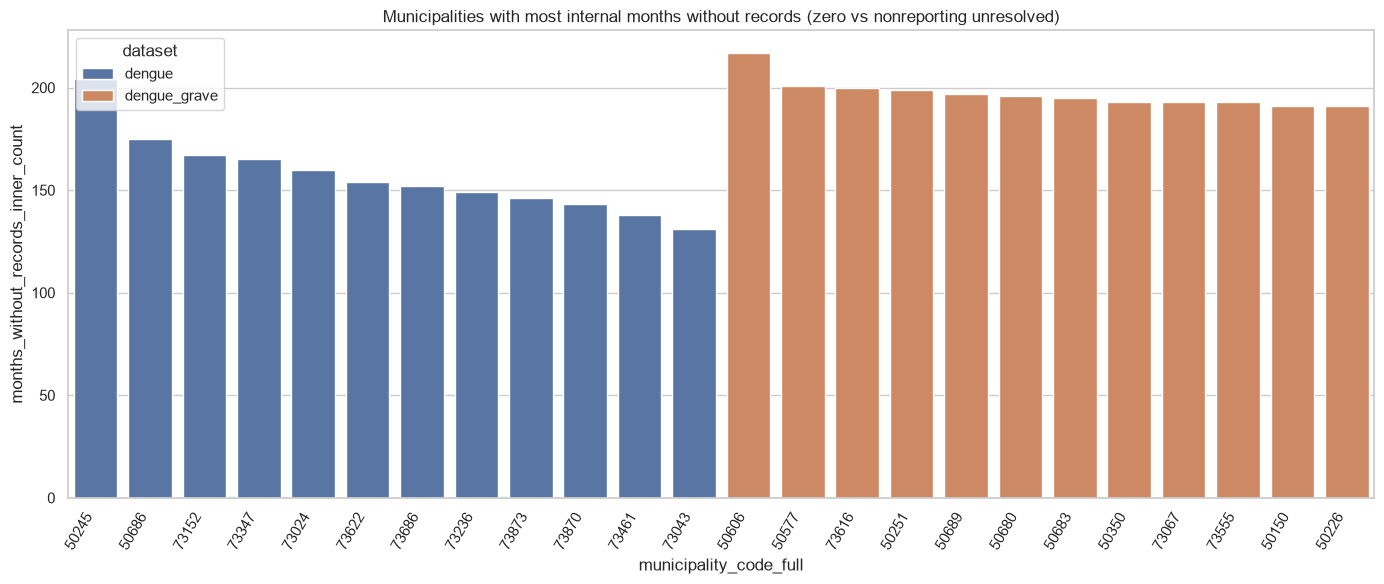

DIVIPOLA-based territorial and temporal diagnostics exported to: /Users/mauriciorodriguez/Projects/AI-Masters/SAT-Dengue-V2/data/interim/stage2_divipola_validation
Expected DIVIPOLA municipalities (target departments): 76


In [10]:
def build_epi_coverage_and_temporal(path: Path, dataset_name: str, expected_codes: set[str], chunk_size: int = 200_000):
    valid_codes = set()
    additional_codes = set()
    exception_counter = Counter()
    contradiction_examples = Counter()

    by_code = {
        code: {
            "records_total": 0,
            "records_ini_interpretable": 0,
            "months_observed": set(),
            "ini_min": None,
            "ini_max": None,
        }
        for code in expected_codes
    }

    global_dates = []

    reader = pd.read_csv(
        path,
        usecols=["COD_DPTO_R", "COD_MUN_R", "Departamento_residencia", "Municipio_residencia", "INI_SIN"],
        dtype=str,
        chunksize=chunk_size,
        low_memory=True,
    )

    for chunk in reader:
        scope_df = classify_residence_scope(chunk)
        ini_dt, ini_missing, ini_invalid = parse_colombian_datetime(chunk["INI_SIN"])

        in_scope = scope_df["in_scope_department"]
        in_scope_rows = scope_df[in_scope].copy()

        if in_scope_rows.empty:
            continue

        status_counts = in_scope_rows["municipality_status"].value_counts()
        exception_counter["missing_code"] += int(status_counts.get("missing", 0))
        exception_counter["unknown_code"] += int(status_counts.get("unknown", 0))
        exception_counter["invalid_code"] += int(status_counts.get("invalid", 0))
        exception_counter["department_conflict"] += int(status_counts.get("blocked_department_conflict", 0))
        exception_counter["missing_department_code"] += int(status_counts.get("blocked_no_valid_department_code", 0))

        conflict_rows = scope_df[in_scope & scope_df["department_code_name_conflict"]]
        if not conflict_rows.empty:
            sample_conf = (
                conflict_rows[["department_code", "department_name"]]
                .value_counts()
                .head(15)
            )
            for (d_code, d_name), count in sample_conf.items():
                contradiction_examples[(str(d_code), str(d_name))] += int(count)

        valid_mask = in_scope & scope_df["municipality_status"].eq("valid")
        if not valid_mask.any():
            continue

        valid_codes_chunk = scope_df.loc[valid_mask, "municipality_code_full"].astype(str)
        valid_codes.update(valid_codes_chunk.unique().tolist())

        chunk_valid_df = pd.DataFrame(
            {
                "code": valid_codes_chunk.values,
                "ini_dt": ini_dt[valid_mask].values,
                "ini_missing": ini_missing[valid_mask].values,
                "ini_invalid": ini_invalid[valid_mask].values,
            }
        )

        for row in chunk_valid_df.itertuples(index=False):
            code = row.code
            if code in expected_codes:
                state = by_code[code]
                state["records_total"] += 1
                if pd.notna(row.ini_dt):
                    state["records_ini_interpretable"] += 1
                    month = pd.Timestamp(row.ini_dt).to_period("M").strftime("%Y-%m")
                    state["months_observed"].add(month)
                    state["ini_min"] = row.ini_dt if state["ini_min"] is None else min(state["ini_min"], row.ini_dt)
                    state["ini_max"] = row.ini_dt if state["ini_max"] is None else max(state["ini_max"], row.ini_dt)
                    global_dates.append(pd.Timestamp(row.ini_dt))
            else:
                additional_codes.add(code)

    expected_missing_codes = sorted(expected_codes.difference(valid_codes))

    if global_dates:
        global_start = min(global_dates)
        global_end = max(global_dates)
        global_months = pd.period_range(global_start.to_period("M"), global_end.to_period("M"), freq="M")
    else:
        global_start = pd.NaT
        global_end = pd.NaT
        global_months = pd.PeriodIndex([], freq="M")

    temporal_rows = []
    for code in sorted(expected_codes):
        state = by_code[code]
        months_observed = sorted(state["months_observed"])

        if state["ini_min"] is not None and state["ini_max"] is not None:
            inner_months = pd.period_range(
                pd.Timestamp(state["ini_min"]).to_period("M"),
                pd.Timestamp(state["ini_max"]).to_period("M"),
                freq="M",
            )
            observed_set = set(months_observed)
            inner_missing = [m.strftime("%Y-%m") for m in inner_months if m.strftime("%Y-%m") not in observed_set]

            if len(global_months):
                pre_months = [m.strftime("%Y-%m") for m in global_months if m < pd.Timestamp(state["ini_min"]).to_period("M")]
                post_months = [m.strftime("%Y-%m") for m in global_months if m > pd.Timestamp(state["ini_max"]).to_period("M")]
            else:
                pre_months = []
                post_months = []
        else:
            inner_missing = []
            pre_months = []
            post_months = []

        temporal_rows.append(
            {
                "dataset": dataset_name,
                "department_code": code[:2],
                "municipality_code_full": code,
                "records_total": state["records_total"],
                "records_ini_interpretable": state["records_ini_interpretable"],
                "window_start": global_start.date().isoformat() if pd.notna(global_start) else "",
                "window_end": global_end.date().isoformat() if pd.notna(global_end) else "",
                "first_ini_interpretable": pd.Timestamp(state["ini_min"]).date().isoformat() if state["ini_min"] is not None else "",
                "last_ini_interpretable": pd.Timestamp(state["ini_max"]).date().isoformat() if state["ini_max"] is not None else "",
                "months_with_records_count": len(months_observed),
                "months_without_records_inner_count": len(inner_missing),
                "months_without_records_pre_count": len(pre_months),
                "months_without_records_post_count": len(post_months),
                "months_without_records_inner_sample": ", ".join(inner_missing[:8]),
                "continuity_note": "indeterminate_without_additional_reporting_context",
            }
        )

    contradiction_rows = [
        {
            "dataset": dataset_name,
            "exception_type": "department_code_name_contradiction",
            "municipality_code_full": "",
            "count": count,
            "details": f"department_code={d_code}, department_name={d_name}",
        }
        for (d_code, d_name), count in contradiction_examples.items()
    ]

    exception_rows = [
        {
            "dataset": dataset_name,
            "exception_type": "expected_code_absent",
            "municipality_code_full": code,
            "count": 1,
            "details": "expected in DIVIPOLA but absent in dataset valid codes",
        }
        for code in expected_missing_codes
    ] + [
        {
            "dataset": dataset_name,
            "exception_type": "additional_code_not_in_divipola",
            "municipality_code_full": code,
            "count": 1,
            "details": "valid code in dataset but not in DIVIPOLA target universe",
        }
        for code in sorted(additional_codes)
    ] + [
        {
            "dataset": dataset_name,
            "exception_type": key,
            "municipality_code_full": "",
            "count": int(value),
            "details": "row-level exception count in in-scope residence rows",
        }
        for key, value in sorted(exception_counter.items())
    ] + contradiction_rows

    summary_rows = [
        {
            "dataset": dataset_name,
            "coverage_status": "expected_present_valid_code",
            "count": len(expected_codes.intersection(valid_codes)),
        },
        {
            "dataset": dataset_name,
            "coverage_status": "expected_absent_valid_code",
            "count": len(expected_missing_codes),
        },
        {
            "dataset": dataset_name,
            "coverage_status": "additional_valid_code_not_in_divipola",
            "count": len(additional_codes),
        },
        {
            "dataset": dataset_name,
            "coverage_status": "row_exceptions_total",
            "count": int(sum(exception_counter.values())),
        },
    ]

    return {
        "valid_codes": valid_codes,
        "temporal_df": pd.DataFrame(temporal_rows),
        "exceptions_df": pd.DataFrame(exception_rows),
        "summary_df": pd.DataFrame(summary_rows),
        "global_start": global_start,
        "global_end": global_end,
    }


def build_climate_coverage_and_temporal(path: Path, expected_codes: set[str], epi_window_start: pd.Timestamp, epi_window_end: pd.Timestamp, chunk_size: int = 250_000):
    valid_codes = set()
    additional_codes = set()
    exception_counter = Counter()
    contradiction_examples = Counter()

    by_code = {
        code: {
            "valid_dates": set(),
            "rows_in_window": 0,
            "rows_with_any_empty": 0,
            "rows_with_all_empty": 0,
            "rows_with_zero_values": 0,
        }
        for code in expected_codes
    }

    global_climate_dates = []

    reader = pd.read_csv(
        path,
        usecols=CLIMATE_USECOLS,
        dtype=str,
        chunksize=chunk_size,
        low_memory=True,
    )

    for chunk in reader:
        dept_code_info = classify_numeric_code(chunk["dpto_ccdgo"], expected_len=2, allow_left_pad=True, unknown_codes={"00"})
        mun_code_info = classify_numeric_code(chunk["mpio_cdpmp"], expected_len=5, allow_left_pad=True, unknown_codes={"00000"})
        dept_name_info = classify_department_name(chunk["dpto_cnmbr"])

        dept_code = dept_code_info["normalized"]
        dept_valid = dept_code_info["status"].eq("valid")
        in_target_dept = dept_valid & dept_code.isin(TARGET_DPTO_CODES.keys())

        dept_name_target = dept_name_info["name_class"].eq("target")
        dept_name_to_code = dept_name_info["normalized"].map(TARGET_DPTO_NAME_TO_CODE).fillna("")
        dept_conflict = in_target_dept & dept_name_target & dept_name_to_code.ne(dept_code)

        exception_counter["department_conflict"] += int(dept_conflict.sum())

        conflict_rows = pd.DataFrame({"department_code": dept_code, "department_name": dept_name_info["normalized"]})[dept_conflict]
        if not conflict_rows.empty:
            sample_conf = conflict_rows.value_counts().head(15)
            for (d_code, d_name), count in sample_conf.items():
                contradiction_examples[(str(d_code), str(d_name))] += int(count)

        target_chunk = pd.DataFrame(
            {
                "code": mun_code_info["normalized"],
                "code_status": mun_code_info["status"],
                "date_raw": normalize_text_series(chunk["date"]),
            }
        )
        for var in CLIMATE_VARS:
            target_chunk[var] = normalize_text_series(chunk[var])

        target_chunk = target_chunk[in_target_dept].copy()
        if target_chunk.empty:
            continue

        status_counts = target_chunk["code_status"].value_counts()
        exception_counter["missing_code"] += int(status_counts.get("missing", 0))
        exception_counter["unknown_code"] += int(status_counts.get("unknown", 0))
        exception_counter["invalid_code"] += int(status_counts.get("invalid_length", 0) + status_counts.get("invalid_chars", 0))

        valid_mask = target_chunk["code_status"].eq("valid") & target_chunk["code"].ne("00000")
        if not valid_mask.any():
            continue

        valid_df = target_chunk[valid_mask].copy()
        valid_codes_chunk = valid_df["code"].astype(str)
        valid_codes.update(valid_codes_chunk.unique().tolist())

        valid_df["date_dt"] = pd.to_datetime(valid_df["date_raw"], format="%Y-%m-%d", errors="coerce")

        for row in valid_df.itertuples(index=False):
            code = row.code
            if pd.notna(row.date_dt):
                global_climate_dates.append(pd.Timestamp(row.date_dt))
            else:
                exception_counter["invalid_or_missing_date"] += 1
                continue

            if code not in expected_codes:
                additional_codes.add(code)
                continue

            if pd.notna(row.date_dt):
                dt = pd.Timestamp(row.date_dt)
                by_code[code]["valid_dates"].add(dt.date())

                in_window = (
                    pd.notna(epi_window_start)
                    and pd.notna(epi_window_end)
                    and (dt >= pd.Timestamp(epi_window_start))
                    and (dt <= pd.Timestamp(epi_window_end))
                )
                if in_window:
                    by_code[code]["rows_in_window"] += 1
                    var_values = [getattr(row, var) for var in CLIMATE_VARS]
                    any_empty = any(v == "" for v in var_values)
                    all_empty = all(v == "" for v in var_values)
                    zero_values = 0
                    for value in var_values:
                        if value == "":
                            continue
                        numeric_val = pd.to_numeric(pd.Series([value]), errors="coerce").iloc[0]
                        if pd.notna(numeric_val) and float(numeric_val) == 0.0:
                            zero_values += 1
                    by_code[code]["rows_with_any_empty"] += int(any_empty)
                    by_code[code]["rows_with_all_empty"] += int(all_empty)
                    by_code[code]["rows_with_zero_values"] += int(zero_values > 0)

    expected_missing_codes = sorted(expected_codes.difference(valid_codes))

    if global_climate_dates:
        climate_start = min(global_climate_dates)
        climate_end = max(global_climate_dates)
    else:
        climate_start = pd.NaT
        climate_end = pd.NaT

    if pd.notna(epi_window_start) and pd.notna(epi_window_end) and pd.notna(climate_start) and pd.notna(climate_end):
        common_start = max(pd.Timestamp(epi_window_start), pd.Timestamp(climate_start))
        common_end = min(pd.Timestamp(epi_window_end), pd.Timestamp(climate_end))
        if common_start <= common_end:
            common_dates = pd.date_range(common_start, common_end, freq="D")
            common_dates_set = set(common_dates.date)
        else:
            common_start = pd.NaT
            common_end = pd.NaT
            common_dates_set = set()
    else:
        common_start = pd.NaT
        common_end = pd.NaT
        common_dates_set = set()

    temporal_rows = []
    for code in sorted(expected_codes):
        state = by_code[code]
        present_dates = state["valid_dates"]
        missing_dates = sorted(common_dates_set.difference(present_dates)) if common_dates_set else []

        temporal_rows.append(
            {
                "dataset": "climate",
                "department_code": code[:2],
                "municipality_code_full": code,
                "window_start": common_start.date().isoformat() if pd.notna(common_start) else "",
                "window_end": common_end.date().isoformat() if pd.notna(common_end) else "",
                "dates_present_count": len(present_dates.intersection(common_dates_set)) if common_dates_set else 0,
                "missing_dates_count": len(missing_dates) if common_dates_set else np.nan,
                "missing_dates_sample": ", ".join(str(d) for d in missing_dates[:8]),
                "rows_in_window": state["rows_in_window"],
                "rows_with_any_climate_empty": state["rows_with_any_empty"],
                "rows_with_all_climate_empty": state["rows_with_all_empty"],
                "rows_with_observed_zero_values": state["rows_with_zero_values"],
                "continuity_note": "indeterminate_without_external_reporting_context",
            }
        )

    contradiction_rows = [
        {
            "dataset": "climate",
            "exception_type": "department_code_name_contradiction",
            "municipality_code_full": "",
            "count": count,
            "details": f"department_code={d_code}, department_name={d_name}",
        }
        for (d_code, d_name), count in contradiction_examples.items()
    ]

    exception_rows = [
        {
            "dataset": "climate",
            "exception_type": "expected_code_absent",
            "municipality_code_full": code,
            "count": 1,
            "details": "expected in DIVIPOLA but absent in climate valid codes",
        }
        for code in expected_missing_codes
    ] + [
        {
            "dataset": "climate",
            "exception_type": "additional_code_not_in_divipola",
            "municipality_code_full": code,
            "count": 1,
            "details": "valid climate code not in DIVIPOLA target universe",
        }
        for code in sorted(additional_codes)
    ] + [
        {
            "dataset": "climate",
            "exception_type": key,
            "municipality_code_full": "",
            "count": int(value),
            "details": "row-level exception count in target department climate rows",
        }
        for key, value in sorted(exception_counter.items())
    ] + contradiction_rows

    summary_rows = [
        {
            "dataset": "climate",
            "coverage_status": "expected_present_valid_code",
            "count": len(expected_codes.intersection(valid_codes)),
        },
        {
            "dataset": "climate",
            "coverage_status": "expected_absent_valid_code",
            "count": len(expected_missing_codes),
        },
        {
            "dataset": "climate",
            "coverage_status": "additional_valid_code_not_in_divipola",
            "count": len(additional_codes),
        },
        {
            "dataset": "climate",
            "coverage_status": "row_exceptions_total",
            "count": int(sum(exception_counter.values())),
        },
    ]

    return {
        "valid_codes": valid_codes,
        "temporal_df": pd.DataFrame(temporal_rows),
        "exceptions_df": pd.DataFrame(exception_rows),
        "summary_df": pd.DataFrame(summary_rows),
        "common_start": common_start,
        "common_end": common_end,
    }


epi_cov_results = {}
for dataset_name in ["dengue", "dengue_grave"]:
    epi_cov_results[dataset_name] = build_epi_coverage_and_temporal(
        data_paths[dataset_name],
        dataset_name,
        EXPECTED_DIVIPOLA_CODES,
    )

all_epi_dates = []
for ds_name in ["dengue", "dengue_grave"]:
    ds_start = epi_cov_results[ds_name]["global_start"]
    ds_end = epi_cov_results[ds_name]["global_end"]
    if pd.notna(ds_start):
        all_epi_dates.append(pd.Timestamp(ds_start))
    if pd.notna(ds_end):
        all_epi_dates.append(pd.Timestamp(ds_end))

if all_epi_dates:
    epi_window_start_for_climate = min(all_epi_dates)
    epi_window_end_for_climate = max(all_epi_dates)
else:
    epi_window_start_for_climate = pd.NaT
    epi_window_end_for_climate = pd.NaT

climate_cov_result = build_climate_coverage_and_temporal(
    data_paths["climate"],
    EXPECTED_DIVIPOLA_CODES,
    epi_window_start_for_climate,
    epi_window_end_for_climate,
)


coverage_table = TARGET_MUNI_TARGET_DF[["department_code", "department_name", "municipality_code_full", "municipality_name"]].drop_duplicates().copy()
coverage_table["present_dengue"] = coverage_table["municipality_code_full"].isin(epi_cov_results["dengue"]["valid_codes"])
coverage_table["present_dengue_grave"] = coverage_table["municipality_code_full"].isin(epi_cov_results["dengue_grave"]["valid_codes"])
coverage_table["present_climate"] = coverage_table["municipality_code_full"].isin(climate_cov_result["valid_codes"])
coverage_table = coverage_table.sort_values(["department_code", "municipality_code_full"], ignore_index=True)

exceptions_df = pd.concat(
    [
        epi_cov_results["dengue"]["exceptions_df"],
        epi_cov_results["dengue_grave"]["exceptions_df"],
        climate_cov_result["exceptions_df"],
    ],
    ignore_index=True,
)

coverage_summary_df = pd.concat(
    [
        epi_cov_results["dengue"]["summary_df"],
        epi_cov_results["dengue_grave"]["summary_df"],
        climate_cov_result["summary_df"],
    ],
    ignore_index=True,
)

temporal_epi_df = pd.concat(
    [
        epi_cov_results["dengue"]["temporal_df"],
        epi_cov_results["dengue_grave"]["temporal_df"],
    ],
    ignore_index=True,
)
temporal_climate_df = climate_cov_result["temporal_df"].copy()

catalog_available_state = "PASS" if bool(DIVIPOLA_VALIDATION_DF["state"].eq("PASS").all()) else "FAIL"
territorial_satisfactory = (
    int(coverage_summary_df.query("coverage_status == 'expected_absent_valid_code'")["count"].sum()) == 0
    and int(coverage_summary_df.query("coverage_status == 'additional_valid_code_not_in_divipola'")["count"].sum()) == 0
    and int(coverage_summary_df.query("coverage_status == 'row_exceptions_total'")["count"].sum()) == 0
)
territorial_state = "PASS" if territorial_satisfactory else "FAIL"

if pd.notna(climate_cov_result["common_start"]) and pd.notna(climate_cov_result["common_end"]):
    temporal_window_state = "PASS"
else:
    temporal_window_state = "BLOCKED"

continuity_summary_df = pd.DataFrame(
    [
        {
            "topic": "catalog_json_structure_and_consistency",
            "state": catalog_available_state,
            "details": "DIVIPOLA estado/conteo/required fields/cross-catalog consistency checks.",
        },
        {
            "topic": "catalog_available_vs_territorial_validation",
            "state": "PASS" if catalog_available_state == "PASS" else "FAIL",
            "details": f"catalog_available_state={catalog_available_state}",
        },
        {
            "topic": "territorial_validation_satisfactory",
            "state": territorial_state,
            "details": "Satisfactory requires no expected absences, additional non-catalog codes or unresolved row-code exceptions. FAIL is a data finding, not failure to execute the diagnostic.",
        },
        {
            "topic": "explicit_common_window_for_climate_continuity",
            "state": temporal_window_state,
            "details": f"common_window_start={climate_cov_result['common_start']}, common_window_end={climate_cov_result['common_end']}",
        },
        {
            "topic": "continuity_interpretation_guardrail",
            "state": "PASS",
            "details": "Missing months and no-record municipalities remain indeterminate without external reporting evidence.",
        },
    ]
)

DIVIPOLA_VALIDATION_DF.to_csv(OUTPUT_DIR / "divipola_catalog_validation.csv", index=False)
DIVIPOLA_COUNTS_DF.to_csv(OUTPUT_DIR / "divipola_department_municipality_counts.csv", index=False)
coverage_table.to_csv(OUTPUT_DIR / "territorial_coverage_by_code.csv", index=False)
exceptions_df.to_csv(OUTPUT_DIR / "territorial_exceptions.csv", index=False)
coverage_summary_df.to_csv(OUTPUT_DIR / "territorial_summary_by_dataset.csv", index=False)
temporal_epi_df.to_csv(OUTPUT_DIR / "temporal_continuity_epi.csv", index=False)
temporal_climate_df.to_csv(OUTPUT_DIR / "temporal_continuity_climate.csv", index=False)
continuity_summary_df.to_csv(OUTPUT_DIR / "coverage_controls_status.csv", index=False)

with (OUTPUT_DIR / "divipola_catalog_metadata.json").open("w", encoding="utf-8") as f:
    json.dump(DIVIPOLA_METADATA, f, ensure_ascii=False, indent=2)


display(Markdown("### Territorial coverage by official code (DIVIPOLA universe)"))
display(coverage_table)

display(Markdown("### Territorial exception taxonomy (sample)"))
display(exceptions_df.head(120))

display(Markdown("### Territorial coverage summary by dataset"))
display(coverage_summary_df)

display(Markdown("### Temporal continuity summary controls"))
display(continuity_summary_df)

if not temporal_epi_df.empty:
    epi_plot_df = (
        temporal_epi_df
        .sort_values(["dataset", "months_without_records_inner_count"], ascending=[True, False])
        .groupby("dataset", group_keys=False)
        .head(12)
    )
    plt.figure(figsize=(14, 6))
    sns.barplot(
        data=epi_plot_df,
        x="municipality_code_full",
        y="months_without_records_inner_count",
        hue="dataset",
    )
    plt.title("Municipalities with most internal months without records (zero vs nonreporting unresolved)")
    plt.ylabel("months_without_records_inner_count")
    plt.xlabel("municipality_code_full")
    plt.xticks(rotation=60, ha="right")
    plt.tight_layout()
    plt.show()

print("DIVIPOLA-based territorial and temporal diagnostics exported to:", OUTPUT_DIR)
print("Expected DIVIPOLA municipalities (target departments):", len(EXPECTED_DIVIPOLA_CODES))

In [11]:
current_alerts_total = int(quality_df["ini_after_fec_not_count"].sum())
previous_alerts_total = 8556

comparison_alerts_df = pd.DataFrame(
    [
        {
            "metric": "INI_SIN > FEC_NOT total alerts (all datasets, in-scope)",
            "previous_reported_value": previous_alerts_total,
            "current_recomputed_value": current_alerts_total,
            "difference": current_alerts_total - previous_alerts_total,
            "interpretation": "Differences can come from corrected residence-scope classification and denominator logic.",
        }
    ]
)

continuity_state_map = {}
if "continuity_summary_df" in globals() and not continuity_summary_df.empty:
    continuity_state_map = dict(zip(continuity_summary_df["topic"], continuity_summary_df["state"]))

territorial_absent_total = int(
    coverage_summary_df.loc[
        coverage_summary_df["coverage_status"].eq("expected_absent_valid_code"),
        "count",
    ].sum()
) if "coverage_summary_df" in globals() else np.nan

territorial_additional_total = int(
    coverage_summary_df.loc[
        coverage_summary_df["coverage_status"].eq("additional_valid_code_not_in_divipola"),
        "count",
    ].sum()
) if "coverage_summary_df" in globals() else np.nan

evidence_states = pd.DataFrame(
    [
        {
            "topic": "CSV structure and required headers",
            "state": "PASS",
            "evidence": "Header checks for dengue, dengue_grave, and climate files were executed.",
        },
        {
            "topic": "DIVIPOLA catalog structure and consistency",
            "state": continuity_state_map.get("catalog_json_structure_and_consistency", "UNVERIFIED"),
            "evidence": "Catalog estado/conteo/required-field/consistency checks exported to divipola_catalog_validation.csv.",
        },
        {
            "topic": "Territorial coverage against DIVIPOLA",
            "state": continuity_state_map.get("territorial_validation_satisfactory", "UNVERIFIED"),
            "evidence": (
                f"Expected-absent total={territorial_absent_total}; additional-valid-code total={territorial_additional_total}; "
                "see territorial_coverage_by_code.csv and territorial_exceptions.csv."
            ),
        },
        {
            "topic": "Temporal continuity diagnostics",
            "state": continuity_state_map.get("explicit_common_window_for_climate_continuity", "UNVERIFIED"),
            "evidence": "Municipality-level continuity artifacts exported for epidemiological and climate data.",
        },
        {
            "topic": "Supplied DANE provenance recorded and hash-bound",
            "state": "PASS" if DIVIPOLA_VALIDATION_DF["state"].eq("PASS").all() else "FAIL",
            "evidence": "URL, download 2026-10-16 and reported version 2026-09-30 supplied by Mauricio; local hashes checked. Historical applicability is not established.",
        },
        {
            "topic": "Residence filtering without code truncation",
            "state": "PASS",
            "evidence": "Synthetic tests passed for valid/missing/invalid/unknown/conflict/truncation-prevention scenarios.",
        },
        {
            "topic": "INI_SIN diagnostics executed (not a consistency approval)",
            "state": "PASS",
            "evidence": "Diagnostics executed; temporal anomalies remain unresolved. No dates were swapped or replaced.",
        },
        {
            "topic": "Training strategy decision",
            "state": "UNVERIFIED",
            "evidence": "Out of scope for this Stage 2 bounded EDA increment.",
        },
    ]
)

display(Markdown("### Evidence states"))
display(evidence_states)

key_metrics = quality_df[
    [
        "dataset",
        "department",
        "records_in_scope",
        "records_with_valid_municipality_code",
        "ini_interpretable_count",
        "ini_missing_count",
        "ini_conversion_error_count",
        "ini_future_vs_cutoff_count",
        "ini_after_fec_not_count",
        "delay_comparable_pairs",
    ]
].copy()

display(Markdown("### Key metrics for documentation update"))
display(key_metrics)

display(Markdown("### Exported Stage 2 continuity and coverage artifacts"))
exported_files_df = pd.DataFrame(
    {
        "relative_path": sorted(
            [str(p.relative_to(repo_root)) for p in OUTPUT_DIR.glob("*.csv")]
            + [str((OUTPUT_DIR / "divipola_catalog_metadata.json").relative_to(repo_root))]
        )
    }
)
display(exported_files_df)

display(Markdown("### Comparison against previously reported 8,556 consistency alerts"))
display(comparison_alerts_df)

print("Notebook execution complete for Stage 2 bounded EDA increment.")

### Evidence states

,topic,state,evidence
0,CSV structure and required headers,PASS,"Header checks for dengue, dengue_grave, and cl..."
1,DIVIPOLA catalog structure and consistency,PASS,Catalog estado/conteo/required-field/consisten...
2,Territorial coverage against DIVIPOLA,FAIL,Expected-absent total=5; additional-valid-code...
3,Temporal continuity diagnostics,PASS,Municipality-level continuity artifacts export...
4,Supplied DANE provenance recorded and hash-bound,PASS,"URL, download 2026-10-16 and reported version ..."
5,Residence filtering without code truncation,PASS,Synthetic tests passed for valid/missing/inval...
6,INI_SIN diagnostics executed (not a consistenc...,PASS,Diagnostics executed; temporal anomalies remai...
7,Training strategy decision,UNVERIFIED,Out of scope for this Stage 2 bounded EDA incr...


### Key metrics for documentation update

,dataset,department,records_in_scope,records_with_valid_municipality_code,ini_interpretable_count,ini_missing_count,ini_conversion_error_count,ini_future_vs_cutoff_count,ini_after_fec_not_count,delay_comparable_pairs
0,dengue,META,106457,106247,106451,6,0,0,3597,106451
1,dengue,TOLIMA,129044,128871,129043,1,0,0,4959,129043
2,dengue_grave,META,1963,1952,1963,0,0,0,0,1963
3,dengue_grave,TOLIMA,2656,2646,2656,0,0,0,0,2656


### Exported Stage 2 continuity and coverage artifacts

,relative_path
0,data/interim/stage2_divipola_validation/covera...
1,data/interim/stage2_divipola_validation/divipo...
2,data/interim/stage2_divipola_validation/divipo...
3,data/interim/stage2_divipola_validation/divipo...
4,data/interim/stage2_divipola_validation/tempor...
5,data/interim/stage2_divipola_validation/tempor...
6,data/interim/stage2_divipola_validation/territ...
7,data/interim/stage2_divipola_validation/territ...
8,data/interim/stage2_divipola_validation/territ...


### Comparison against previously reported 8,556 consistency alerts

,metric,previous_reported_value,current_recomputed_value,difference,interpretation
0,"INI_SIN > FEC_NOT total alerts (all datasets, ...",8556,8556,0,Differences can come from corrected residence-...


Notebook execution complete for Stage 2 bounded EDA increment.


## Results, limitations, and review point

### Observations
- Results in this notebook are descriptive and scoped to Stage 2 data understanding.
- Dengue and severe dengue records were analyzed separately.
- Territorial coverage was contrasted against DIVIPOLA expected municipalities for Tolima and Meta.
- Temporal continuity was reported independently from territorial presence.

### Limitations
- DIVIPOLA identity, structure and supplied provenance are recorded. Publication version is attributed to Mauricio; historical applicability is not independently established.
- This notebook does not perform cleaning, imputation, deduplication, integration, endemic-channel construction, or modeling.
- Missing months and municipalities without records remain indeterminate without external reporting evidence.

### Pending decisions
- Historical and operational interpretation policy for temporal gaps and reporting lags.
- Final municipality eligibility criteria for downstream target/model stages.
- Training strategy choice (shared vs departmental vs municipal) remains open.

### Review framing
- Observation: exported tables and notebook outputs.
- Interpretation: bounded to executed diagnostics only.
- Implication: readiness of evidence for Stage 2 review, not Stage 2 closure.
- Pending decision: Mauricio and ChatGPT review before any next increment authorization.

**Stop point:** Stage 2 remains open and G2 is not approved.

The municipal-coverage diagnostic is complete with documented exceptions; this is not a claim of complete data quality. Next: Mauricio is obtaining the original 2013 SIVIGILA source for comparison. Date swapping remains an unapproved hypothesis.


## Stage 2 Targeted Investigation: `INI_SIN > FEC_NOT` (2012-2014)

This section investigates the 8,556 dengue records with `INI_SIN > FEC_NOT` under the approved analytical constraints:

- Residence municipality focus (`COD_DPTO_R`, `COD_MUN_R`), Meta and Tolima.
- `INI_SIN` remains the epidemiological date reference.
- No automatic date correction is applied to source files.
- New yearly downloads (2012, 2013, 2014) are treated as reference snapshots, not automatic historical truth.

The section consumes reproducible artifacts generated in `data/interim/stage2_dengue_date_investigation/` and compares:

1. Baseline anomaly replication in consolidated export.
2. Temporal behavior by year/source.
3. Record-level correspondence quality (only where key reliability is defendable).
4. Scenario sensitivity (A/B/C and conditional D).

In [15]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

candidate_dirs = [
    Path("data/interim/stage2_dengue_date_investigation"),
    Path("../data/interim/stage2_dengue_date_investigation"),
]
investigation_dir = None
for c in candidate_dirs:
    if c.exists():
        investigation_dir = c
        break
if investigation_dir is None:
    investigation_dir = candidate_dirs[0]

required_files = {
    "inventory": "source_inventory.csv",
    "inventory_meta": "source_inventory_metadata.json",
    "baseline_summary": "baseline_anomaly_summary.csv",
    "baseline_department": "baseline_anomaly_by_department.csv",
    "temporal_summary": "temporal_comparability_summary.csv",
    "comparison_match": "comparison_match_outcomes.csv",
    "comparison_dates": "comparison_date_pairs.csv",
    "sensitivity_full": "sensitivity_scenarios_municipio_mes.csv",
    "sensitivity_shift": "sensitivity_top_months_shift.csv",
    "sensitivity_notes": "sensitivity_scenario_notes.csv",
}

missing = [name for name in required_files.values() if not (investigation_dir / name).exists()]
if missing:
    raise FileNotFoundError(f"Missing investigation artifacts: {missing}")

inventory = pd.read_csv(investigation_dir / required_files["inventory"])
with (investigation_dir / required_files["inventory_meta"]).open("r", encoding="utf-8") as f:
    inventory_meta = json.load(f)
baseline_summary = pd.read_csv(investigation_dir / required_files["baseline_summary"])
baseline_department = pd.read_csv(investigation_dir / required_files["baseline_department"])
temporal_summary = pd.read_csv(investigation_dir / required_files["temporal_summary"])
comparison_match = pd.read_csv(investigation_dir / required_files["comparison_match"])
comparison_dates = pd.read_csv(investigation_dir / required_files["comparison_dates"])
sensitivity_full = pd.read_csv(investigation_dir / required_files["sensitivity_full"])
sensitivity_shift = pd.read_csv(investigation_dir / required_files["sensitivity_shift"])
sensitivity_notes = pd.read_csv(investigation_dir / required_files["sensitivity_notes"])

print("Investigation artifact directory:", investigation_dir)
print("Target years detected in yearly references:", inventory_meta.get("target_years_detected"))
print("Yearly reference files detected:", inventory_meta.get("target_year_references_count"))
print("\nConsolidated baseline summary:")
display(baseline_summary[baseline_summary["dataset"] == "dengue"])
print("\nBaseline by department (Meta/Tolima):")
display(baseline_department[baseline_department["dataset"] == "dengue"][["department_name", "comparable_records", "affected_records", "affected_pct"]])

print("\nMatch taxonomy by yearly source:")
display(comparison_match.sort_values(["source_year", "match_class"]))

print("\nDate-pair comparison metrics:")
display(comparison_dates.sort_values(["source_year", "metric"]))

Investigation artifact directory: ../data/interim/stage2_dengue_date_investigation
Target years detected in yearly references: [2012, 2013, 2014]
Yearly reference files detected: 3

Consolidated baseline summary:


,dataset,scope,total_scope_records,comparable_records,affected_records,affected_pct_over_comparable
0,dengue,Meta+Tolima residence,235501,235494,8556,3.633214



Baseline by department (Meta/Tolima):


,department_name,comparable_records,affected_records,affected_pct
0,Meta,106451,3597,3.379019
1,Tolima,129043,4959,3.842905



Match taxonomy by yearly source:


,source_year,source_name,comparison_mode,match_class,record_count,note
0,2012,Dengue_Datos_2012_210.xlsx,record_level_keyed,left_only,135,NaN
2,2012,Dengue_Datos_2012_210.xlsx,record_level_keyed,matched_unique,10715,NaN
1,2012,Dengue_Datos_2012_210.xlsx,record_level_keyed,right_only,0,NaN
3,2013,Dengue_Datos_2013_210.xlsx,record_level_keyed,left_only,208,NaN
5,2013,Dengue_Datos_2013_210.xlsx,record_level_keyed,matched_unique,20296,NaN
4,2013,Dengue_Datos_2013_210.xlsx,record_level_keyed,right_only,0,NaN
6,2014,Dengue_Datos_2014_210.xlsx,record_level_keyed,left_only,217,NaN
8,2014,Dengue_Datos_2014_210.xlsx,record_level_keyed,matched_unique,15216,NaN
7,2014,Dengue_Datos_2014_210.xlsx,record_level_keyed,right_only,0,NaN



Date-pair comparison metrics:


,source_year,source_name,metric,record_count
2,2012,Dengue_Datos_2012_210.xlsx,different_parsed_dates_any_field,1
3,2012,Dengue_Datos_2012_210.xlsx,exact_swapped_pairs,481
0,2012,Dengue_Datos_2012_210.xlsx,matched_records,10715
1,2012,Dengue_Datos_2012_210.xlsx,same_parsed_dates_both_fields,10714
4,2012,Dengue_Datos_2012_210.xlsx,same_raw_ini,10715
5,2012,Dengue_Datos_2012_210.xlsx,same_raw_not,10715
8,2013,Dengue_Datos_2013_210.xlsx,different_parsed_dates_any_field,3
9,2013,Dengue_Datos_2013_210.xlsx,exact_swapped_pairs,66
6,2013,Dengue_Datos_2013_210.xlsx,matched_records,20296
7,2013,Dengue_Datos_2013_210.xlsx,same_parsed_dates_both_fields,20293


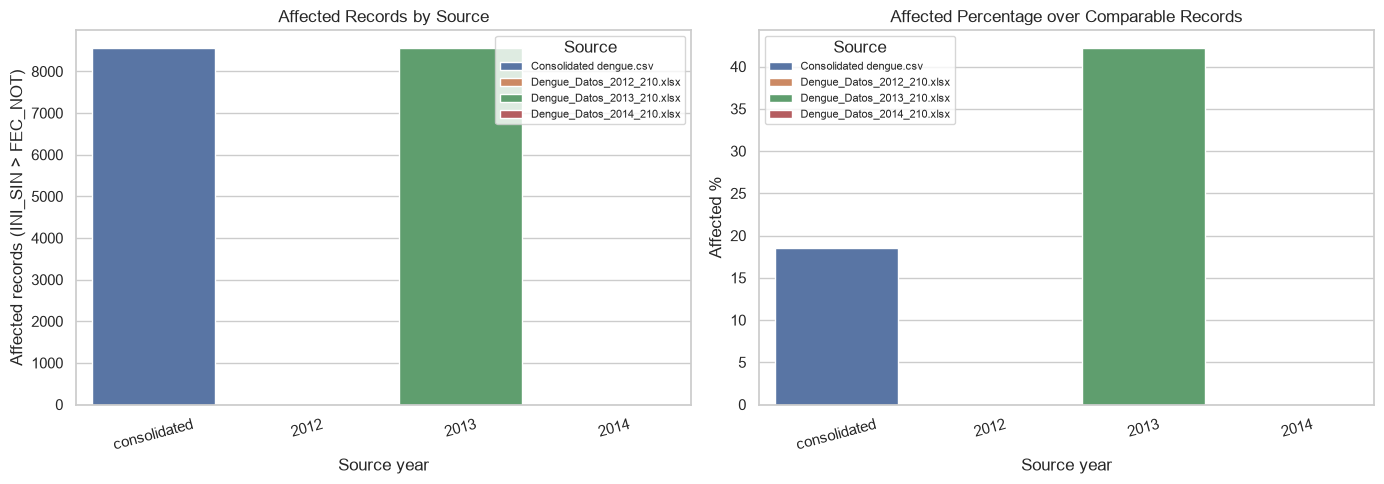

,scenario,retained_records,base_records,total_abs_delta,net_delta
0,A_keep_current,46269.0,46269.0,0,0.0
1,B_swap_affected_only,46269.0,46269.0,8576,0.0
2,C_exclude_affected,37713.0,46269.0,8556,-8556.0
3,D_source_2013_reference,46269.0,46269.0,0,0.0


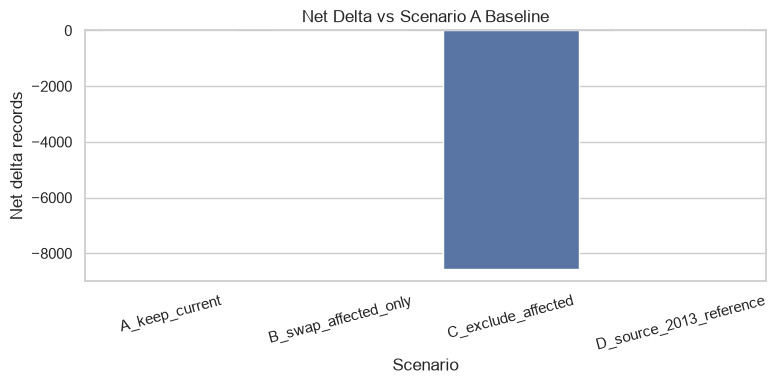

Top municipality-month absolute deltas per scenario (sample):


,scenario,municipality_code,year_month,count_records,base_count,delta_abs,delta_rel_pct,abs_delta
0,A_keep_current,0,2011-12,1.0,1.0,0.0,0.000000,0.0
1,A_keep_current,0,2012-01,1.0,1.0,0.0,0.000000,0.0
2,A_keep_current,0,2012-02,5.0,5.0,0.0,0.000000,0.0
3,A_keep_current,0,2012-03,2.0,2.0,0.0,0.000000,0.0
4,A_keep_current,0,2012-04,2.0,2.0,0.0,0.000000,0.0
5,A_keep_current,0,2012-05,4.0,4.0,0.0,0.000000,0.0
6,A_keep_current,0,2012-06,2.0,2.0,0.0,0.000000,0.0
7,A_keep_current,0,2012-08,1.0,1.0,0.0,0.000000,0.0
8,A_keep_current,0,2012-10,1.0,1.0,0.0,0.000000,0.0
9,A_keep_current,0,2012-11,3.0,3.0,0.0,0.000000,0.0


Scenario notes:


,scenario,note
0,A_keep_current,Baseline with current INI_SIN values.
1,B_swap_affected_only,Swapping removes negative delays by constructi...
2,C_exclude_affected,Exclusion changes analysis volume and can supp...
3,D_source_2013_reference,Built using matched 2013 source dates with fal...
4,_meta,coverage_d_records=20293


In [16]:
# Temporal anomaly comparison across sources/years.
plot_temporal = temporal_summary.copy()
plot_temporal["source_year_label"] = plot_temporal["source_year_hint"].fillna(0).astype(int).astype(str)
plot_temporal.loc[plot_temporal["source_year_hint"].isna(), "source_year_label"] = "consolidated"

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=plot_temporal,
    x="source_year_label",
    y="affected_records",
    hue="source_label",
    ax=axes[0],
)
axes[0].set_title("Affected Records by Source")
axes[0].set_xlabel("Source year")
axes[0].set_ylabel("Affected records (INI_SIN > FEC_NOT)")
axes[0].tick_params(axis="x", rotation=15)
axes[0].legend(title="Source", fontsize=8)

sns.barplot(
    data=plot_temporal,
    x="source_year_label",
    y="affected_pct",
    hue="source_label",
    ax=axes[1],
)
axes[1].set_title("Affected Percentage over Comparable Records")
axes[1].set_xlabel("Source year")
axes[1].set_ylabel("Affected %")
axes[1].tick_params(axis="x", rotation=15)
axes[1].legend(title="Source", fontsize=8)

plt.tight_layout()
plt.show()

# Scenario impact summary without filling missing periods as zeros.
scenario_overview = (
    sensitivity_full.groupby("scenario", dropna=False)
    .agg(
        retained_records=("count_records", "sum"),
        base_records=("base_count", "sum"),
        total_abs_delta=("delta_abs", lambda s: int(np.abs(s).sum())),
    )
    .reset_index()
)
scenario_overview["net_delta"] = scenario_overview["retained_records"] - scenario_overview["base_records"]
display(scenario_overview.sort_values("scenario"))

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=scenario_overview, x="scenario", y="net_delta", ax=ax)
ax.set_title("Net Delta vs Scenario A Baseline")
ax.set_xlabel("Scenario")
ax.set_ylabel("Net delta records")
ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

print("Top municipality-month absolute deltas per scenario (sample):")
display(sensitivity_shift.sort_values(["scenario", "abs_delta"], ascending=[True, False]).head(20))

print("Scenario notes:")
display(sensitivity_notes)